<a href="https://colab.research.google.com/github/joela03/EEEM030-GroupAssignment2/blob/main/EEEM030_GroupAssignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EEEM030 Group Assignment 2: Speech Recognition

In [ ]:
# Colab only: fetch the repo (data + notebook) and move into it. Does nothing when run locally inside the repo.
import os, sys, subprocess
if 'google.colab' in sys.modules and not os.path.isdir('DevelopmentSet'):
    subprocess.run(['git', 'clone', 'https://github.com/joela03/EEEM030-GroupAssignment2'], check=True)
    os.chdir('EEEM030-GroupAssignment2')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torchaudio', 'librosa', 'soundfile'], check=True)
print('Working directory:', os.getcwd(), '| DevelopmentSet found:', os.path.isdir('DevelopmentSet'))

Working directory: /content/EEEM030-GroupAssignment2 | DevelopmentSet found: True


Isolated-word recognition (11 words) with an FFN and a Transformer.

**Team members / chapter authors:** _TBC_

## 0. Setup

### 0.1 Imports

In [ ]:
from pathlib import Path
from collections import Counter
from io import BytesIO
import hashlib
import json
import math
import platform
import time
import urllib.request
import zipfile
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import soundfile as sf
import torch
import torchaudio
from torch import nn
from IPython.display import Audio, Markdown, display

SEED = 30
torch.manual_seed(SEED)
torch.set_num_threads(2)  # Small CPU operations do not need many threads.
DTYPE = torch.float32
DEVICE = torch.device('cpu')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})

print('Python:', platform.python_version())
print('PyTorch:', torch.__version__, '| TorchAudio:', torchaudio.__version__)
print('Device:', DEVICE, '| dtype:', DTYPE, '| seed:', SEED)

Python: 3.13.18
PyTorch: 2.14.1+cpu | TorchAudio: 2.11.0+cpu
Device: cpu | dtype: torch.float32 | seed: 30


## Part 2: Data Preparation & Feed-Forward Network

### 2.1 Load speech recordings & parse labels

In [ ]:
def parse_recording(path):
    speaker, recording, word = path.stem.split('_')

    return {
        'path': path,
        'speaker': speaker,
        'recording': int(recording[1:]),
        'word': word
    }

paths = sorted(Path("DevelopmentSet").glob("*.mp3"))

records = [parse_recording(path) for path in paths]

# Speakers list
all_speakers = sorted({r['speaker'] for r in records})

# Words list
all_words = sorted({r['word'] for r in records})
word_to_label = {word: i for i, word in enumerate(all_words)}

print("Speakers:", all_speakers)
print("Words:", all_words)

# Nbr of recordings
print("Total recordings:", len(records))

counts = Counter((r['speaker'], r['word']) for r in records)

print("Recordings per speaker:", set(counts.values()))

Speakers: ['sp01a', 'sp02a', 'sp03a', 'sp04a', 'sp05a', 'sp06a', 'sp07a', 'sp08a', 'sp09a', 'sp10a', 'sp11a', 'sp12a', 'sp13a', 'sp14a', 'sp15a', 'sp16a', 'sp17a', 'sp18a', 'sp19a', 'sp20a', 'sp21a', 'sp22a', 'sp23a', 'sp24a', 'sp25a', 'sp26a', 'sp27a', 'sp28a', 'sp29a', 'sp30a']
Words: ['had', 'hard', 'head', 'heard', 'heed', 'hid', 'hoard', 'hod', 'hood', 'hud', 'whod']
Total recordings: 330
Recordings per speaker: {1}


### 2.2 Train / validation / test split (speaker-independent)

In [ ]:
TRAIN_SPEAKERS = {'sp01a', 'sp02a', 'sp03a', 'sp04a', 'sp05a', 'sp06a', 'sp07a', 'sp08a', 'sp09a', 'sp10a',
                  'sp11a', 'sp12a', 'sp13a', 'sp14a', 'sp15a', 'sp16a', 'sp17a', 'sp18a', 'sp19a', 'sp20a',
                  'sp21a', 'sp22a', 'sp23a', 'sp24a', 'sp25a', 'sp26a', 'sp27a', 'sp28a'}
VAL_SPEAKERS = {'sp29a'}
TEST_SPEAKERS = {'sp30a'}

# Training speakers must not appear in validation or test.
assert TRAIN_SPEAKERS.isdisjoint(VAL_SPEAKERS | TEST_SPEAKERS)

# Validation and test speakers must not overlap.
assert VAL_SPEAKERS.isdisjoint(TEST_SPEAKERS)

# The three splits must collectively contain exactly the dataset's speakers.
assert TRAIN_SPEAKERS | VAL_SPEAKERS | TEST_SPEAKERS == set(all_speakers)

split_speakers = {'train': TRAIN_SPEAKERS, 'validation': VAL_SPEAKERS, 'test': TEST_SPEAKERS}
split_indices = {
    split: torch.tensor([i for i, r in enumerate(records) if r['speaker'] in speakers],
                        dtype=torch.long)
    for split, speakers in split_speakers.items()
}
for split, indices in split_indices.items():
    labels = Counter(records[i]['word'] for i in indices.tolist())
    print(f'{split:<11}: {len(indices):4d} recordings | per-word counts: {dict(sorted(labels.items()))}')
    # Check that the split contains all eleven word labels with no other labels.
    assert set(labels) == set(all_words)


train      :  308 recordings | per-word counts: {'had': 28, 'hard': 28, 'head': 28, 'heard': 28, 'heed': 28, 'hid': 28, 'hoard': 28, 'hod': 28, 'hood': 28, 'hud': 28, 'whod': 28}
validation :   11 recordings | per-word counts: {'had': 1, 'hard': 1, 'head': 1, 'heard': 1, 'heed': 1, 'hid': 1, 'hoard': 1, 'hod': 1, 'hood': 1, 'hud': 1, 'whod': 1}
test       :   11 recordings | per-word counts: {'had': 1, 'hard': 1, 'head': 1, 'heard': 1, 'heed': 1, 'hid': 1, 'hoard': 1, 'hod': 1, 'hood': 1, 'hud': 1, 'whod': 1}


Focus on one waveform

Filename: sp05a_w05_hard.mp3
Waveform shape: (11520,) | duration: 0.72 s


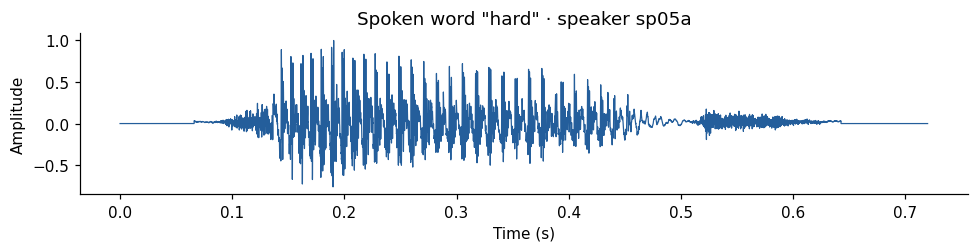

In [ ]:
SAMPLE_RATE = 16000

def load_waveform(path):
    samples, sample_rate = sf.read(str(path), dtype='float32', always_2d=True)
    waveform = torch.from_numpy(samples).mean(dim=1).contiguous()  # (N,), mono
    if sample_rate != SAMPLE_RATE:
        raise ValueError(f'{path.name}: expected {SAMPLE_RATE} Hz; got {sample_rate} Hz.')
    if waveform.numel() == 0 or not torch.isfinite(waveform).all():
        raise ValueError(f'{path.name}: empty or non-finite waveform.')
    return waveform

example_record = next(r for r in records if r['word'] == 'hard' and r['speaker'] == 'sp05a')
waveform = load_waveform(example_record['path'])
time_axis = torch.arange(waveform.numel()) / SAMPLE_RATE
print('Filename:', example_record['path'].name)
print('Waveform shape:', tuple(waveform.shape), '| duration:', round(len(waveform) / SAMPLE_RATE, 3), 's')
fig, ax = plt.subplots(figsize=(9, 2.4))
ax.plot(time_axis, waveform, linewidth=0.8, color='#245e9b')
ax.set(xlabel='Time (s)', ylabel='Amplitude', title='Spoken word "hard" · speaker sp05a')
fig.tight_layout()
plt.show()
display(Audio(waveform.numpy(), rate=SAMPLE_RATE))


### 2.3 Log-mel spectrogram extraction (80 mel bins, 25 ms window, 10 ms hop)

In [ ]:
N_MELS = 80
WIN_LENGTH = round(0.025 * SAMPLE_RATE)  # 200
HOP_LENGTH = round(0.010 * SAMPLE_RATE)  # 80
N_FFT = 512

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE, n_fft=N_FFT, win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH, f_min=0.0, f_max=SAMPLE_RATE / 2,
    n_mels=N_MELS, power=2.0, center=True, pad_mode='constant',
    norm='slaney', mel_scale='slaney',
)

def log_mel_spectrogram(waveform):
    mel_power = mel_transform(waveform)                    # (80, T)
    log_power = 10.0 * torch.log10(mel_power.clamp_min(1e-10))
    log_mel = (log_power - log_power.max()).clamp_min(-80.0)
    assert log_mel.ndim == 2 and log_mel.shape[0] == N_MELS
    assert torch.isfinite(log_mel).all()
    return log_mel

example_log_mel = log_mel_spectrogram(waveform)
print('Log-mel (F, T):', tuple(example_log_mel.shape))
print('A single frame:', tuple(example_log_mel[:, 0].shape))
print('Range (relative dB):', float(example_log_mel.min()), 'to', float(example_log_mel.max()))


Log-mel (F, T): (80, 73)
A single frame: (80,)
Range (relative dB): -80.0 to 0.0


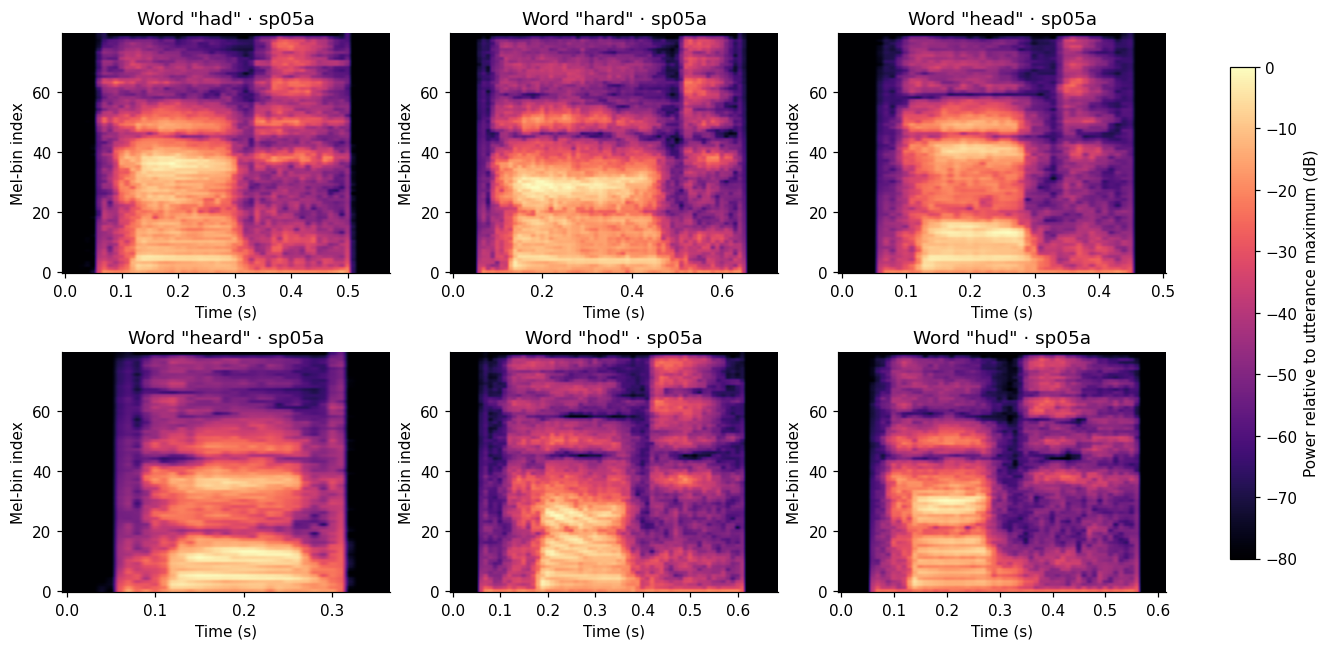

In [ ]:
# Six training examples; validation and test examples are not used for visual choices.
# These examples are the ones choosen for the attention mechanism
X_attention_mechanism = []
Y_attention_mechanism = []

fig, axes = plt.subplots(2, 3, figsize=(12, 5.8), layout='constrained')
for nbr, ax in zip([0, 1, 2, 3, 7, 9], axes.flat):
    record = next(r for r in records if r['word'] == all_words[nbr] and r['speaker'] == 'sp05a')
    mel = log_mel_spectrogram(load_waveform(record['path']))

    #For the attention mechanism, we store the mel spectrograms and their corresponding words in lists
    X_attention_mechanism.append(mel)
    Y_attention_mechanism.append(word_to_label[record['word']])
    # With centred frames, frame centres are at t * hop / sample_rate.
    half_hop = HOP_LENGTH / (2 * SAMPLE_RATE)
    end = (mel.shape[1] - 1) * HOP_LENGTH / SAMPLE_RATE + half_hop
    image = ax.imshow(mel.numpy(), origin='lower', aspect='auto', cmap='magma',
                      vmin=-80, vmax=0, extent=(-half_hop, end, -0.5, N_MELS - 0.5))
    ax.set(title=f'Word "{all_words[nbr]}" · sp05a', xlabel='Time (s)', ylabel='Mel-bin index')
fig.colorbar(image, ax=axes, label='Power relative to utterance maximum (dB)', shrink=0.88)
plt.show()

### 2.4 Fixed-length representation (pooling / pad-truncate / sequence)

Mean pooling for each mel spectrogram ==> (80,1) vectors

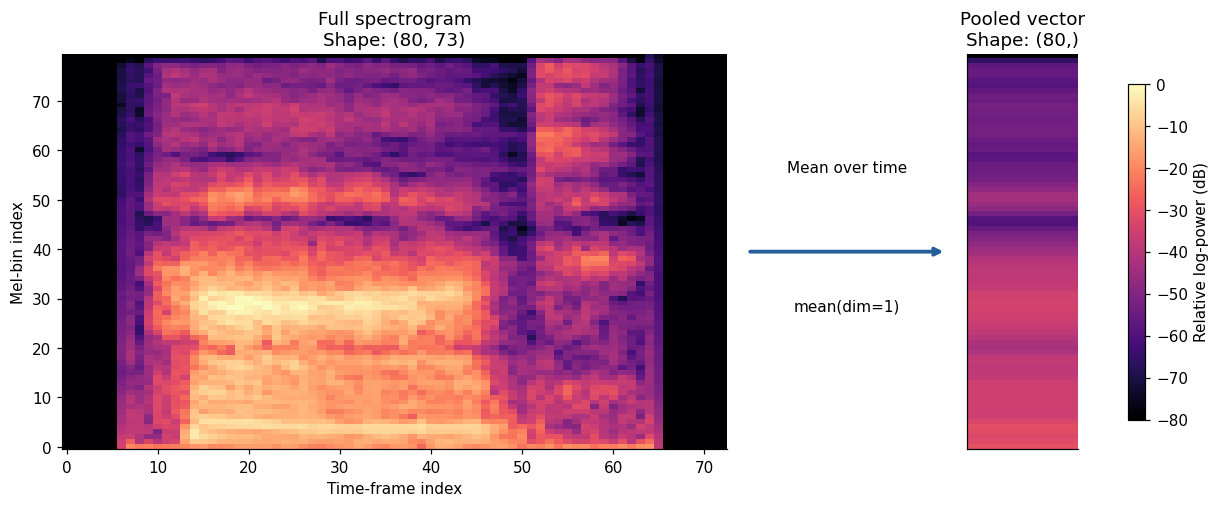

Before pooling: (80, 73) | after: (80,)


In [ ]:
# Average over time, retaining one value per mel bin.
pooled_example = example_log_mel.mean(dim=1)
assert pooled_example.shape == (80,)

fig = plt.figure(figsize=(11, 4.5), layout='constrained')
grid = fig.add_gridspec(1, 3, width_ratios=[6, 2, 1])

ax_spec = fig.add_subplot(grid[0, 0])
ax_arrow = fig.add_subplot(grid[0, 1])
ax_vector = fig.add_subplot(grid[0, 2], sharey=ax_spec)

# A shared colour scale makes the two representations comparable.
colour_settings = dict(
    origin='lower',
    aspect='auto',
    cmap='magma',
    vmin=-80,
    vmax=0,
    interpolation='nearest',
)

# Full spectrogram: (80, T)
image = ax_spec.imshow(
    example_log_mel.detach().cpu().numpy(),
    **colour_settings,
)
ax_spec.set(
    title=f'Full spectrogram\nShape: {tuple(example_log_mel.shape)}',
    xlabel='Time-frame index',
    ylabel='Mel-bin index',
)

# Arrow showing the pooling operation.
ax_arrow.set_axis_off()
ax_arrow.annotate(
    '',
    xy=(0.95, 0.5),
    xytext=(0.05, 0.5),
    xycoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=2.5, color='#245e9b'),
)
ax_arrow.text(
    0.5, 0.70, 'Mean over time',
    ha='center', transform=ax_arrow.transAxes,
)
ax_arrow.text(
    0.5, 0.35, 'mean(dim=1)',
    ha='center', transform=ax_arrow.transAxes,
)

# Pooled vector: (80,), displayed as an (80, 1) column.
ax_vector.imshow(
    pooled_example.detach().cpu().numpy()[:, None],
    **colour_settings,
)
ax_vector.set(
    title=f'Pooled vector\nShape: {tuple(pooled_example.shape)}',
    xticks=[],
)
ax_vector.tick_params(axis='y', left=False, labelleft=False)

fig.colorbar(
    image,
    ax=[ax_spec, ax_vector],
    label='Relative log-power (dB)',
    shrink=0.85,
)

plt.show()

print(
    'Before pooling:', tuple(example_log_mel.shape),
    '| after:', tuple(pooled_example.shape),
)

In [ ]:
# Shape notation:
# B = number of recordings, F = number of mel bins (80)
# T_i = number of time frames in recording i (varies between recordings)

start_time = time.perf_counter()
sequences = []
pooled_vectors = []

for i, record in enumerate(records):
    # Shape: (F, T_i) — mel bins × time frames
    log_mel = log_mel_spectrogram(load_waveform(record['path']))

    # Shape: (T_i, F) — time frames × mel bins
    sequences.append(log_mel.T.contiguous())

    # Shape: (F,) — one average value per mel bin, pooled over time
    pooled_vectors.append(log_mel.mean(dim=1))

    if (i + 1) % 1000 == 0:
        print(f'Processed {i + 1}/{len(records)} recordings')

# Shape: (B, F) = (330, 80) — recordings × pooled mel features
X_raw = torch.stack(pooled_vectors).to(dtype=DTYPE)

# Shape: (B,) = (330,) — one digit label per recording
# Create a mapping between words and integer labels
print([(all_words[i], i) for i in range(len(all_words))])
y_all = torch.tensor(
    [word_to_label[r['word']] for r in records],
    dtype=torch.long,
)

assert X_raw.shape == (330, 80) and y_all.shape == (330,)
assert torch.isfinite(X_raw).all()

# Shape: (B,) — number of time frames in each recording
lengths = torch.tensor([sequence.shape[0] for sequence in sequences])

print(f'Feature extraction took {time.perf_counter() - start_time:.1f} s')
print('X_raw (recordings, mel features):', X_raw.shape)
print('Labels (recordings,):', y_all.shape)
print(
    'Time frames per recording: min / median / max =',
    lengths.min().item(),
    lengths.median().item(),
    lengths.max().item(),
)

[('had', 0), ('hard', 1), ('head', 2), ('heard', 3), ('heed', 4), ('hid', 5), ('hoard', 6), ('hod', 7), ('hood', 8), ('hud', 9), ('whod', 10)]
Feature extraction took 0.4 s
X_raw (recordings, mel features): torch.Size([330, 80])
Labels (recordings,): torch.Size([330])
Time frames per recording: min / median / max = 33 55 83


Standardize

In [ ]:
train_indices = split_indices['train']
feature_mean = X_raw[train_indices].mean(dim=0, keepdim=True)  # (1, 80)
feature_std = X_raw[train_indices].std(dim=0, unbiased=False, keepdim=True).clamp_min(1e-5)

assert X_raw.shape == (330, 80)
assert feature_mean.shape == (1, 80), feature_mean.shape
assert feature_std.shape == (1,80), feature_std.shape

X_all = (X_raw - feature_mean) / feature_std

X_train, y_train = X_all[train_indices], y_all[train_indices]
X_val, y_val = X_all[split_indices['validation']], y_all[split_indices['validation']]
X_test, y_test = X_all[split_indices['test']], y_all[split_indices['test']]


assert X_train.shape == (308, 80) and X_val.shape == X_test.shape == (11, 80)
assert torch.isfinite(X_all).all()
assert X_train.mean(dim=0).abs().max() < 1e-4
assert (X_train.std(dim=0, unbiased=False) - 1).abs().max() < 1e-4
print('Training mean, first five features:', X_train.mean(dim=0)[:5])
print('Training std, first five features: ', X_train.std(dim=0, unbiased=False)[:5])
print('Prepared tensors: X_train, y_train; X_val, y_val; X_test, y_test\n')
print('---\n\nShapes:\n- Training set: X_train(recordings, mel features):', X_train.shape, ', y_train(recordings,):', y_train.shape)
print('- Validation set: X_val(recordings, mel features):', X_val.shape, ', y_val(recordings,):', y_val.shape)
print('- Test set: X_test(recordings, mel features):', X_test.shape, ', y_test(recordings,):', y_test.shape)


Training mean, first five features: tensor([-6.1927e-07, -4.8458e-07, -5.6353e-07, -7.4932e-07,  2.9106e-07])
Training std, first five features:  tensor([1., 1., 1., 1., 1.])
Prepared tensors: X_train, y_train; X_val, y_val; X_test, y_test

---

Shapes:
- Training set: X_train(recordings, mel features): torch.Size([308, 80]) , y_train(recordings,): torch.Size([308])
- Validation set: X_val(recordings, mel features): torch.Size([11, 80]) , y_val(recordings,): torch.Size([11])
- Test set: X_test(recordings, mel features): torch.Size([11, 80]) , y_test(recordings,): torch.Size([11])


The different sets are ready to be used. Each tensor X contains vectors with dimensions (80,). These vectors are time-averaged representations of the mel-spectrograms for each audio file. The lists Y contain the corresponding words. Three sets are available:
- training set, speaker 1 to 28 : X_train, y _train
- validation, speaker 29: X_val, y_val
- test set, speaker 30: X_test, y_test

Regarding tensors y, here is the correspondence between the words and the numbers:

0='had', 1='hard', 2='head', 3='heard', 4='heed', 5='hid', 6='hoard', 7='hod', 8='hood', 9='hud', 10='whod'


### 2.5 Plot example mel-spectrograms with labels

### 2.6 MLP from scratch (NumPy): forward pass

In [ ]:

INPUT_DIM = X_train.shape[1]
HIDDEN_DIMS = (64, 32)
NUM_CLASSES = len(all_words)
LAYER_DIMS = (INPUT_DIM, *HIDDEN_DIMS, NUM_CLASSES)


def relu(z):
    return np.maximum(z, 0.0)


def log_softmax(z):
    z_shift = z - z.max(axis=-1, keepdims=True)
    return z_shift - np.log(np.exp(z_shift).sum(axis=-1, keepdims=True))


def softmax(z):
    return np.exp(log_softmax(z))


class NumpyMLP:
    def __init__(self, layer_dims, seed=SEED, dtype=np.float64):
        rng = np.random.default_rng(seed)
        self.layer_dims = tuple(layer_dims)
        self.W, self.b = [], []
        for d_in, d_out in zip(self.layer_dims[:-1], self.layer_dims[1:]):
            # He initialisation for ReLU
            self.W.append((rng.standard_normal((d_out, d_in)) * np.sqrt(2.0 / d_in)).astype(dtype))
            self.b.append(np.zeros(d_out, dtype=dtype))

    @property
    def num_parameters(self):
        return sum(W.size + b.size for W, b in zip(self.W, self.b))

    def forward(self, X, return_cache=False):
        single = X.ndim == 1
        h = X[None, :] if single else X                # (B, 80)
        cache = {'h': [h], 'z': []}
        n_layers = len(self.W)
        for l, (W, b) in enumerate(zip(self.W, self.b), start=1):
            z = h @ W.T + b                            # (B, d_l)
            cache['z'].append(z)
            h = relu(z) if l < n_layers else z         # hidden: ReLU; output: linear logits
            cache['h'].append(h)
        cache['logits'] = h                            # (B, 11)
        probs = softmax(h)                             # (B, 11); each row sums to 1
        if single:
            probs = probs[0]
        return (probs, cache) if return_cache else probs

In [ ]:
np_mlp = NumpyMLP(LAYER_DIMS)
X_train_np = X_train.numpy().astype(np.float64)        # (308, 80)

# Dimension counting, checked against the table above.
print('Layer dims:', LAYER_DIMS)
for l, (W, b) in enumerate(zip(np_mlp.W, np_mlp.b), start=1):
    print(f'  Layer {l}: W{l} {W.shape}, b{l} {b.shape} -> {W.size + b.size:,} parameters')
expected = sum(d_in * d_out + d_out for d_in, d_out in zip(LAYER_DIMS[:-1], LAYER_DIMS[1:]))
assert np_mlp.num_parameters == expected
print(f'Total parameters: {np_mlp.num_parameters:,}')

# Forward pass on the whole training set.
probs_np, cache_np = np_mlp.forward(X_train_np, return_cache=True)
print('\nForward pass, batch of training vectors:')
print('  input  h0:', cache_np['h'][0].shape)
for l, z in enumerate(cache_np['z'], start=1):
    print(f'  layer {l} z{l}:', z.shape)
print('  softmax  :', probs_np.shape)

assert probs_np.shape == (len(X_train_np), NUM_CLASSES)
assert np.allclose(probs_np.sum(axis=1), 1.0)          # valid distributions
assert np.isfinite(probs_np).all() and (probs_np > 0).all()

# Untrained, so accuracy should be close to chance (1/11, about 9%).
untrained_acc = (probs_np.argmax(axis=1) == y_train.numpy()).mean()
print(f'\nUntrained training accuracy: {untrained_acc:.1%} (chance = {1 / NUM_CLASSES:.1%})')

Layer dims: (80, 64, 32, 11)
  Layer 1: W1 (64, 80), b1 (64,) -> 5,184 parameters
  Layer 2: W2 (32, 64), b2 (32,) -> 2,080 parameters
  Layer 3: W3 (11, 32), b3 (11,) -> 363 parameters
Total parameters: 7,627

Forward pass, batch of training vectors:
  input  h0: (308, 80)
  layer 1 z1: (308, 64)
  layer 2 z2: (308, 32)
  layer 3 z3: (308, 11)
  softmax  : (308, 11)

Untrained training accuracy: 9.7% (chance = 9.1%)


### 2.7 MLP in PyTorch (`nn.Module`)

In [ ]:

class SpeechFFN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(80, 64),  # First layer (input layer)
            nn.ReLU(),

            nn.Linear(64, 32),  # Second layer
            nn.ReLU(),

            nn.Linear(32, 11)   # Third layer (output layer)
        )

    def forward(self, x):
        return self.network(x)


model = SpeechFFN().to(device=DEVICE, dtype=DTYPE)

print(model)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

SpeechFFN(
  (network): Sequential(
    (0): Linear(in_features=80, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=11, bias=True)
  )
)


In [ ]:
output = model(X_train)

print(output.shape)
print("Number of parameter:",sum(p.numel() for p in model.parameters()))

torch.Size([308, 11])
Number of parameter: 7627


In [ ]:

def accuracy(model, X, y):

    model.eval()

    with torch.no_grad():
        outputs = model(X)
        predictions = torch.argmax(outputs, dim=1)

        correct = (predictions == y).sum().item()
        total = y.size(0)

    return 100 * correct / total


print(f"Untrained training set accuracy: {accuracy(model, X_train, y_train):.2f}%")


Untrained training set accuracy: 10.39%


### 2.8 Worked numerical check: NumPy vs PyTorch outputs

### 2.9 Shape diagram / dimension counting

## Part 3: Training with Backpropagation & SGD

### 3.1 NumPy MLP: backpropagation by hand

#### 3.1.1 Gradient derivation (cross-entropy + softmax, chain rule)

#### 3.1.2 Backward pass implementation

#### 3.1.3 Vanilla SGD / mini-batch training loop

#### 3.1.4 Loss & accuracy tracking (train / validation)

### 3.2 PyTorch MLP training

#### 3.2.1 Training with `torch.optim.SGD`

#### 3.2.2 Training with Adam

#### 3.2.3 Regularisation: weight decay & dropout

#### 3.2.4 Augmentation: SpecAugment / additive noise

### 3.3 Learning-rate schedules & early stopping

### 3.4 Results: loss & accuracy curves

### 3.5 Comparison table (accuracy, confusion matrix, parameters, training time)

### 3.6 Discussion: effect of dropout / SpecAugment on train–validation gap

## Part 4: Attention Mechanism

### 4.1 Scaled dot-product attention (from scratch)

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V.
$$

In [ ]:
import math
## source: Tutorial_3_Attention_Mechanisms.ipynb
def scaled_dot_product_attention(q, k, v):
    """Calculate attention outputs and weights.

    Works with:
        One head:       (N, d_k).
        Batched heads:  (B, M, N, d_k).

    Values may have a different feature dimension, d_v.
    """
    d_k = q.shape[-1]

    # Compare every query with every key.
    scores = q @ k.transpose(-2, -1)  # (..., N, N).

    # Scale the scores.
    scores = scores / math.sqrt(d_k)

    # Convert scores into weights across the keys.
    weights = torch.softmax(scores, dim=-1)  # (..., N, N).

    # Combine the value vectors.
    output = weights @ v  # (..., N, d_v).

    return output, weights


### 4.2 Extend to multi-head attention
- nn.MultiheadAttention or build a new one based on scaled_dot_product_attention(q, k, v)?

In [ ]:
# Copy Tutorial_3_Attention_Mechanisms.ipynb or simply
# multihead_attn = nn.MultiheadAttention(embed_dim, num_heads)
# attn_output, attn_output_weights = multihead_attn(q, k, v)

### 4.3 Apply self-attention to a short sequence of mel frames (or the time dimension of a spectrogram), in order to visualise the attention weight matrix for a few utterances
- a short sequence of mel frames (do I need to pick, or the sequence is short already?)
- a few utterances? one batch/clip per utterance?
- does not say how many heads, I pressume n_head = 1

In [ ]:
# Create an untrained attention module with repeatable initial weights.
SEED
D_MODEL = N_MELBIN
DEVICE
N_HEADS = 1
N_UTTER = BATCH_SIZE # assuming 1 batch for 1 utterance
NAME = 'Utterance'
x # Shape (batch/N_UTTER, n_melFrame, d_model/n_melBin)

# select utterance and melFrame for example utter:0~? & frame:20~60
R_U = [0, N_UTTER]
R_F = [20, 60]
selected_x = x[R_F[0]:R_F[1], R_U[0]:R_U[1], :]
tokens =

torch.manual_seed(SEED)
attention = nn.MultiheadAttention(
    embed_dim=D_MODEL,  # 128 features per token.
    num_heads=N_HEADS,  # 4 heads, each with 32 features.
    batch_first = True
).to(DEVICE)

attention.eval()

    # tokens contains the audio patch embeddings created earlier.
with torch.no_grad():
    attended_tokens, attention_weights = attention(selected_x, selected_x, selected_x, average_attn_weights=False)

    # print('Input tokens (B, N, D):', tuple(tokens.shape))
    # print('Output tokens (B, N, D):', tuple(attended_tokens.shape))
    # print(
    #     'Attention weights (B, heads, queries, keys):',
    #     tuple(attention_weights.shape),
    # )

    # # Each attention row should sum to one.
    # row_sums = attention_weights.sum(dim=-1)
    # torch.testing.assert_close(row_sums, torch.ones_like(row_sums))

    # print('\nVerified: each query’s attention weights sum to 1.')

# Select the first recording and retain all heads.
weights_to_plot = []
for i in range(0,N_UTTER):
    weights_to_plot[i] = attention_weights[i, 0].detach().cpu()
    # Shape: (N_HEADS, N_TOKENS, N_TOKENS).

fig, axes = plt.subplots(
    1, 1,
    figsize=(14, 4),
    layout='constrained',
    squeeze=False,
)

# Use the same colour scale across all frame.
minimum = weights_to_plot.min().item()
maximum = weights_to_plot.max().item()

# PLOT PER UTTERANCE GRAPH
for utter, ax in enumerate(axes[0]):
    image = ax.imshow(
        weights_to_plot[utter].numpy(),
        origin='upper',
        aspect='equal',
        cmap='Blues',
        vmin=minimum,
        vmax=maximum,
    )
    ax.set(
        title= NAME + f' {utter + 1}',
        xlabel='Key token index',
        ylabel='Query token index',
    )

fig.colorbar(
    image,
    ax=list(axes[0]),
    label='Attention weight',
    shrink=0.8,
)
fig.suptitle(
    'Untrained self-attention: one matrix per ' + NAME,
    fontweight='bold',
)
plt.show()

print(f'Observed weight range: {minimum:.5f} to {maximum:.5f}')
print(
    f'Uniform attention would assign '
    f'{1 / tokens.shape[1]:.5f} to each key.'
)

SyntaxError: invalid syntax (1325489003.py, line 14)

### 4.4 Worked example: take a 4–8 frame toy sequence, compute Q, K, V projections, attention weights and output by hand (or with detailed print statements)

In [ ]:
# pick batch/utter = 0, frame 20 to 23 I guess, give me an x of (1 utterance, 4 melframes, n_melbin) aka (4, D_MODEL)
x_toy
# step:
# 1. q, k, v = x
# 2. follow def scaled_dot_product_attention(q, k, v):
# d_k = q.shape[-1]

# # Compare every query with every key.
# scores = q @ k.transpose(-2, -1)  # (..., N, N).

# # Scale the scores.
# scores = scores / math.sqrt(d_k)

# # Convert scores into weights across the keys.
# weights = torch.softmax(scores, dim=-1)  # (..., N, N).

# # Combine the value vectors.
# output = weights @ v  # (..., N, d_v).

# return output, weights


### 4.4.1 Verification against implementation

In [ ]:
# run
attention = nn.MultiheadAttention(
    embed_dim=D_MODEL,
    num_heads=1,
    batch_first=True
)
o_x_toy, w_x_toy = attention(x_toy, x_toy, x_toy, average_attn_weights=False)
# compare o_x_toy, w_x_toy with the hand cal

## Part 5: Basic Transformer Encoder for Mel-Spectrograms

**Balaji (Part 5).** The MLP of Parts 2-3 sees only a *time-averaged* 80-dimensional vector, so it throws away the temporal structure of the word. Here we build a small **Transformer encoder** that reads the *whole sequence* of log-mel frames.

**Pipeline** ($B$ = batch size, $T$ = mel frames, $F=80$ mel bins, $d$ = model width, $T'$ = tokens after subsampling):

```
x (B,T,80)
  -> Conv1d(k=3, stride 2) + ReLU  x2         (B, T/4, d)     5.2  front-end: shortens the sequence
  -> + positional encoding                    (B, T/4, d)     5.1  tells attention WHERE each token is
  -> [ MHSA -> Add&Norm -> FFN -> Add&Norm ]  x2              5.3  two encoder layers
  -> masked mean-pool over time               (B, d)          5.4
  -> Linear(d, 11)                            (B, 11)         logits for the 11 words
```

**Design choices (and why).** Only 308 training recordings exist, so the model is deliberately small: $d=64$, 4 heads ($d_k=16$), FFN width 128, 2 layers (about 96k parameters), dropout 0.1, AdamW weight decay, SpecAugment and early stopping on the validation speaker.

**Variable length.** Recordings have 33-83 frames. Batches are zero-padded and a *padding mask* is carried through every stage (convolutions, attention, pooling) so padding never influences the result. This is verified numerically in 5.4.

**Run order.** Part 5 only needs the cells up to 2.4 (feature extraction), 2.7 (`SpeechFFN`, used as the 5.7 baseline) and `scaled_dot_product_attention` from 4.1 (optional cross-check). It does **not** depend on the unfinished cells of Part 4.

#### 5.0 Sequence data for the Transformer

Part 2 produced `sequences`, a list of `(T_i, 80)` log-mel tensors. We standardise each mel bin with the mean/std of **all training frames** (training speakers only, so nothing leaks from validation/test), then wrap the data so a batch can be zero-padded on demand.

In [ ]:
import copy
import numpy as np
import torch.nn.functional as F

N_FEATS = sequences[0].shape[1]          # 80 mel bins
N_CLASSES = len(all_words)               # 11 words


def fit_standardiser(indices):
    """Per-mel-bin mean/std over every frame of the given recordings -> two (1, 80) tensors."""
    frames = torch.cat([sequences[i] for i in indices], dim=0)           # (sum_i T_i, 80)
    return frames.mean(0, keepdim=True), frames.std(0, unbiased=False, keepdim=True).clamp_min(1e-5)


class SequenceDataset:
    """Standardised variable-length log-mel sequences. `batch()` zero-pads to the longest item."""

    def __init__(self, indices, mean, std):
        self.indices = [int(i) for i in indices]                          # row numbers in `records`
        self.seqs = [((sequences[i] - mean) / std).to(DTYPE) for i in self.indices]   # (T_i, 80)
        self.labels = y_all[torch.tensor(self.indices)]                  # (N,)
        self.lengths = torch.tensor([s.shape[0] for s in self.seqs])     # (N,)

    def __len__(self):
        return len(self.seqs)

    def batch(self, positions):
        """positions: list of ints (0..N-1) -> x (B, T_max, 80), lengths (B,), labels (B,)"""
        lens = self.lengths[positions]
        x = torch.zeros(len(positions), int(lens.max()), N_FEATS, dtype=DTYPE)   # 0 = training mean
        for r, p in enumerate(positions):
            x[r, :lens[r]] = self.seqs[p]
        return x.to(DEVICE), lens.to(DEVICE), self.labels[positions].to(DEVICE)


seq_mean, seq_std = fit_standardiser(split_indices['train'].tolist())            # TRAINING statistics only
tf_train = SequenceDataset(split_indices['train'].tolist(), seq_mean, seq_std)
tf_val = SequenceDataset(split_indices['validation'].tolist(), seq_mean, seq_std)
tf_test = SequenceDataset(split_indices['test'].tolist(), seq_mean, seq_std)

frames_train = torch.cat(tf_train.seqs)
assert frames_train.mean(0).abs().max() < 1e-3 and (frames_train.std(0, unbiased=False) - 1).abs().max() < 1e-3
for name, ds in [('train', tf_train), ('validation', tf_val), ('test', tf_test)]:
    print(f'{name:<10}: {len(ds):3d} recordings | frames per recording min/median/max = '
          f'{ds.lengths.min().item()}/{int(ds.lengths.median())}/{ds.lengths.max().item()}')
x_demo, len_demo, y_demo = tf_train.batch([0, 1, 2, 3])
print('Example batch ->', 'x', tuple(x_demo.shape), '| lengths', len_demo.tolist(), '| labels', y_demo.tolist())

train     : 308 recordings | frames per recording min/median/max = 33/55/83
validation:  11 recordings | frames per recording min/median/max = 44/58/69
test      :  11 recordings | frames per recording min/median/max = 33/40/47
Example batch -> x (4, 73, 80) | lengths [73, 62, 73, 62] | labels [4, 5, 2, 0]


### 5.1 Positional encodings (sinusoidal / learned)

Self-attention treats its input as an unordered *set*: shuffling the frames would shuffle the output in the same way. But word identity depends on **order** (e.g. the formant movement in "hoard" vs "hod"), so we add a position-dependent vector to every token.

**Sinusoidal encoding** (Vaswani et al., 2017), for position $pos$ and feature pair $i$:

$$PE_{(pos,\,2i)}=\sin\!\big(pos/10000^{2i/d}\big),\qquad PE_{(pos,\,2i+1)}=\cos\!\big(pos/10000^{2i/d}\big)$$

Each feature pair is a sine/cosine of a different frequency (from fast to slow, like the digits of a clock). Because $\sin(a+b)$ and $\cos(a+b)$ are linear in $\sin a,\cos a$, the encoding of position $pos+k$ is a fixed rotation of the encoding of $pos$, so *relative* offsets are easy for attention to learn. It has no parameters and works for any length.

**Learned encoding** is an `nn.Embedding(max_len, d)` trained with the rest of the model. Both are implemented; the model uses `pos='sinusoidal'` by default because with only 308 training recordings and about 14 tokens per word, a learned table has very little data to learn from.

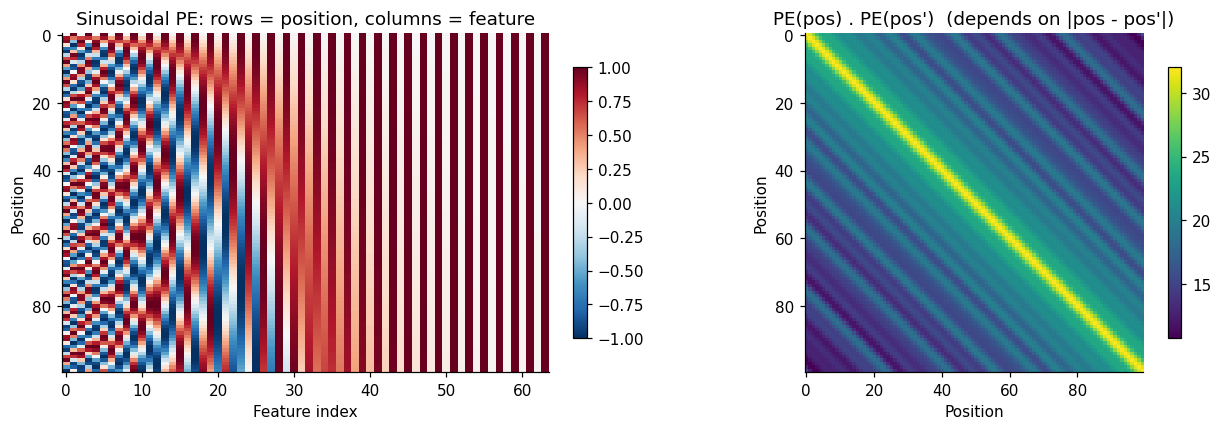

In [ ]:
class SinusoidalPositionalEncoding(nn.Module):
    """Fixed sin/cos positional encoding; adds PE[pos] to every token. Input/output: (B, T, d)."""

    def __init__(self, d_model, max_len=1000):
        super().__init__()
        assert d_model % 2 == 0, 'd_model must be even for sin/cos pairs'
        pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)                          # (max_len, 1)
        inv_freq = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * inv_freq)                                                # even dims
        pe[:, 1::2] = torch.cos(pos * inv_freq)                                                # odd dims
        self.register_buffer('pe', pe, persistent=False)                                       # not trained

    def forward(self, x):
        assert x.size(1) <= self.pe.size(0), 'sequence longer than max_len'
        return x + self.pe[: x.size(1)]


class LearnedPositionalEncoding(nn.Module):
    """Trainable position embedding table (alternative to the sinusoidal version)."""

    def __init__(self, d_model, max_len=1000):
        super().__init__()
        self.table = nn.Embedding(max_len, d_model)
        nn.init.normal_(self.table.weight, std=0.02)

    def forward(self, x):
        positions = torch.arange(x.size(1), device=x.device)
        return x + self.table(positions)


# --- checks -------------------------------------------------------------------------------
pe_layer = SinusoidalPositionalEncoding(64)
pe = pe_layer.pe[:100]                                                       # (100, 64)
assert torch.allclose(pe[0, 0::2], torch.zeros(32)) and torch.allclose(pe[0, 1::2], torch.ones(32))  # sin 0, cos 0
assert pe.abs().max() <= 1.0 and pe_layer(torch.zeros(2, 30, 64)).shape == (2, 30, 64)

# --- visualise ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
im = axes[0].imshow(pe.numpy(), aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set(title='Sinusoidal PE: rows = position, columns = feature', xlabel='Feature index', ylabel='Position')
fig.colorbar(im, ax=axes[0], shrink=0.8)
sim = pe @ pe.T                                                              # (100, 100) dot-products
im = axes[1].imshow(sim.numpy(), cmap='viridis')
axes[1].set(title='PE(pos) . PE(pos\')  (depends on |pos - pos\'|)', xlabel='Position', ylabel='Position')
fig.colorbar(im, ax=axes[1], shrink=0.8)
plt.show()

### 5.2 Convolutional subsampling front-end (optional)

At a 10 ms hop a word of 0.55 s has about 55 frames, and neighbouring frames are highly redundant. A **convolutional front-end** with stride 2 does three jobs: it (i) projects 80 mel bins to $d$ features, (ii) mixes each frame with its neighbours (kernel 3), and (iii) halves the time axis, which matters because attention cost grows with $T'^2$.

We use `Conv1d` over time (the 80 mel bins are the input channels). With kernel 3, padding 1 and stride 2 the output length is

$$T_{out}=\left\lfloor \frac{T+2\cdot 1-3}{2}\right\rfloor+1=\left\lfloor\frac{T-1}{2}\right\rfloor+1 .$$

Two layers give $T'\approx T/4$, so each token summarises about 7 input frames (70 ms plus the 25 ms window), roughly the scale of a phoneme transition.

**Padding detail.** When recordings of different length share a batch, the padded region would otherwise leak into the real frames: after the first convolution the padded positions hold `ReLU(bias)` rather than 0, and the second convolution would read them. We therefore update the lengths after each stride-2 layer and **zero every padded position** after each convolution. Then a recording gives exactly the same output alone or in a padded batch (tested in 5.4).

`n_conv` is a parameter (0 = just a per-frame linear projection, 1, 2, 3) so 5.8 can measure how sequence length affects accuracy and compute.

In [ ]:
def subsampled_length(lengths, n_conv):
    """Frames -> tokens after n_conv stride-2 convolutions (kernel 3, padding 1): floor((T-1)/2)+1 each time."""
    for _ in range(n_conv):
        lengths = (lengths - 1) // 2 + 1
    return lengths


class ConvSubsampling(nn.Module):
    """(B, T, n_mels) -> (B, T', d_model) with T' ~ T / 2**n_conv, plus the new valid lengths."""

    def __init__(self, n_mels, d_model, n_conv=2):
        super().__init__()
        self.n_conv = n_conv
        self.convs, self.strides = nn.ModuleList(), []
        if n_conv == 0:                                         # no subsampling: per-frame linear projection
            self.convs.append(nn.Conv1d(n_mels, d_model, kernel_size=1))
            self.strides.append(1)
        else:
            c_in = n_mels
            for _ in range(n_conv):
                self.convs.append(nn.Conv1d(c_in, d_model, kernel_size=3, stride=2, padding=1))
                self.strides.append(2)
                c_in = d_model

    def forward(self, x, lengths):
        x = x.transpose(1, 2)                                   # (B, n_mels, T): mel bins act as channels
        for conv, stride in zip(self.convs, self.strides):
            x = F.relu(conv(x))                                 # (B, d, T_out)
            if stride == 2:
                lengths = (lengths - 1) // 2 + 1
            valid = torch.arange(x.size(-1), device=x.device)[None, :] < lengths[:, None]   # (B, T_out)
            x = x * valid[:, None, :]                           # zero the padded positions
        return x.transpose(1, 2), lengths                       # (B, T', d), (B,)


# --- check shapes against the formula, using the real range of recording lengths -----------
front_demo = ConvSubsampling(N_FEATS, 64, n_conv=2)
h_demo, l_demo = front_demo(x_demo, len_demo)
assert h_demo.shape == (4, int(subsampled_length(len_demo, 2).max()), 64)
print(f'{"frames T":>9} | ' + ' | '.join(f'n_conv={n}' for n in range(4)))
for T in (33, int(tf_train.lengths.median()), 83):
    print(f'{T:>9} | ' + ' | '.join(f'{int(subsampled_length(torch.tensor(T), n)):>7}' for n in range(4)))

 frames T | n_conv=0 | n_conv=1 | n_conv=2 | n_conv=3
       33 |      33 |      17 |       9 |       5
       55 |      55 |      28 |      14 |       7
       83 |      83 |      42 |      21 |      11


### 5.3 Transformer encoder block (MHSA + residual + LayerNorm, FFN + residual + LayerNorm)

**Scaled dot-product attention** (written from scratch, no `nn.MultiheadAttention`):

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}}\Big)V$$

Every token emits a query $q$ ("what am I looking for?"), a key $k$ ("what do I contain?") and a value $v$ ("what do I pass on?"). The score $q\cdot k/\sqrt{d_k}$ says how relevant token $j$ is to token $i$; the softmax turns scores into weights that sum to 1 across keys; the output of token $i$ is the weighted average of all value vectors. Dividing by $\sqrt{d_k}$ keeps the scores at unit variance so the softmax does not saturate (discussed in the group discussion questions).

**Padding mask.** Scores of padded *keys* are set to $-\infty$ before the softmax, so their weight is exactly 0 and real frames never attend to padding.

**Multi-head attention.** Instead of one attention over $d$ dimensions, we project to $h$ heads of size $d_k=d/h$, run attention in each head in parallel (each can specialise, e.g. onset vs vowel centre), concatenate, and mix with an output matrix:

$$\operatorname{head}_i=\operatorname{Attention}(XW_i^Q,XW_i^K,XW_i^V),\qquad \operatorname{MHSA}(X)=[\operatorname{head}_1;\dots;\operatorname{head}_h]\,W^O .$$

In code the $h$ per-head matrices are one `Linear(d, d)` whose output is reshaped `(B,T,d) -> (B,h,T,d_k)`.

**Encoder layer** (post-LN, as in Vaswani et al. 2017):

$$X'=\operatorname{LN}\big(X+\operatorname{Dropout}(\operatorname{MHSA}(X))\big),\qquad X''=\operatorname{LN}\big(X'+\operatorname{Dropout}(\operatorname{FFN}(X'))\big),\qquad \operatorname{FFN}(x)=W_2\,\operatorname{ReLU}(W_1x+b_1)+b_2 .$$

The residual connections give gradients a direct path through the stack, LayerNorm keeps activations well scaled, and the position-wise FFN adds non-linearity applied to every token independently. Attention is the only place where tokens exchange information.

*Attribution:* Part 4.1 (`scaled_dot_product_attention`, adapted from Tutorial_3_Attention_Mechanisms.ipynb) defines the same maths. The version below is written independently for this chapter because it needs two extra features: the padding mask and an `attention_mode='uniform'` switch used for the 5.8 ablation. It is cross-checked against 4.1 and against PyTorch's `nn.MultiheadAttention` (used **only as a test reference**).

In [ ]:
def masked_scaled_dot_product_attention(q, k, v, key_padding_mask=None, mode='learned', dropout_p=0.0, training=False):
    """softmax(q k^T / sqrt(d_k)) v with an optional padding mask.

    q, k, v          : (B, H, T, d_k)  -- batch, heads, tokens, per-head features
    key_padding_mask : (B, T) bool, True = real token, False = padding
    mode             : 'learned' = ordinary attention; 'uniform' = every real token gets equal weight
                       (ablation: keeps the architecture but removes content-based attention)
    returns          : output (B, H, T, d_k), weights (B, H, T, T) with rows summing to 1
    """
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)                      # (B, H, T, T)
    if mode == 'uniform':
        scores = torch.zeros_like(scores)
    if key_padding_mask is not None:
        scores = scores.masked_fill(~key_padding_mask[:, None, None, :], float('-inf'))   # block padded keys
    weights = torch.softmax(scores, dim=-1)                                # normalise over the keys
    out = F.dropout(weights, p=dropout_p, training=training) @ v           # weighted sum of the values
    return out, weights


class MultiHeadSelfAttention(nn.Module):
    """Multi-head self-attention built from nn.Linear projections (no nn.MultiheadAttention)."""

    def __init__(self, d_model, n_heads, dropout=0.0, mode='learned'):
        super().__init__()
        assert d_model % n_heads == 0, 'd_model must be divisible by n_heads'
        self.h, self.d_k, self.mode, self.dropout_p = n_heads, d_model // n_heads, mode, dropout
        self.w_q, self.w_k, self.w_v, self.w_o = (nn.Linear(d_model, d_model) for _ in range(4))

    def _split_heads(self, x):                                             # (B, T, d) -> (B, H, T, d_k)
        B, T, _ = x.shape
        return x.view(B, T, self.h, self.d_k).transpose(1, 2)

    def forward(self, x, key_padding_mask=None):
        B, T, d = x.shape
        q, k, v = self._split_heads(self.w_q(x)), self._split_heads(self.w_k(x)), self._split_heads(self.w_v(x))
        ctx, weights = masked_scaled_dot_product_attention(q, k, v, key_padding_mask, self.mode,
                                                           self.dropout_p, self.training)
        ctx = ctx.transpose(1, 2).contiguous().view(B, T, d)               # concatenate heads: (B, T, d)
        return self.w_o(ctx), weights


class TransformerEncoderLayer(nn.Module):
    """MHSA + residual + LayerNorm, then position-wise FFN + residual + LayerNorm (post-LN)."""

    def __init__(self, d_model, n_heads, d_ff, dropout=0.1, attention_mode='learned'):
        super().__init__()
        self.attn = MultiHeadSelfAttention(d_model, n_heads, dropout, attention_mode)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, key_padding_mask=None):
        a, weights = self.attn(x, key_padding_mask)
        x = self.norm1(x + self.drop(a))                                   # residual + LayerNorm
        x = self.norm2(x + self.drop(self.ffn(x)))                         # residual + LayerNorm
        return x, weights


# --- correctness checks -------------------------------------------------------------------
torch.manual_seed(SEED)
d_t, h_t = 32, 4
mine = MultiHeadSelfAttention(d_t, h_t).eval()
x_t = torch.randn(3, 9, d_t)
len_t = torch.tensor([9, 6, 4])
mask_t = torch.arange(9)[None, :] < len_t[:, None]                         # (3, 9) True = real
out_m, w_m = mine(x_t, mask_t)

# (1) agrees with PyTorch's reference implementation when given the same weights (test only)
ref = nn.MultiheadAttention(d_t, h_t, batch_first=True).eval()
with torch.no_grad():
    ref.in_proj_weight.copy_(torch.cat([mine.w_q.weight, mine.w_k.weight, mine.w_v.weight]))
    ref.in_proj_bias.copy_(torch.cat([mine.w_q.bias, mine.w_k.bias, mine.w_v.bias]))
    ref.out_proj.weight.copy_(mine.w_o.weight)
    ref.out_proj.bias.copy_(mine.w_o.bias)
    out_r, w_r = ref(x_t, x_t, x_t, key_padding_mask=~mask_t, average_attn_weights=False)
torch.testing.assert_close(out_m[mask_t], out_r[mask_t], atol=1e-5, rtol=1e-4)    # compare real tokens
torch.testing.assert_close(w_m, w_r, atol=1e-6, rtol=1e-4)

# (2) each row of weights sums to 1 and padded keys receive exactly 0
torch.testing.assert_close(w_m.sum(-1), torch.ones(3, h_t, 9))
assert (w_m.masked_select(~mask_t[:, None, None, :].expand_as(w_m)) == 0).all()

# (3) agrees with the Part 4.1 function when there is no padding (skipped if that cell has not been run)
if 'scaled_dot_product_attention' in globals():
    q_t = torch.randn(2, h_t, 7, d_t // h_t)
    o41, w41 = scaled_dot_product_attention(q_t, q_t, q_t)
    o51, w51 = masked_scaled_dot_product_attention(q_t, q_t, q_t)
    torch.testing.assert_close(o41, o51)
    torch.testing.assert_close(w41, w51)
    print('Matches Part 4.1 scaled_dot_product_attention.')

# (4) the encoder layer keeps the shape
layer_t, _ = TransformerEncoderLayer(d_t, h_t, 64)(x_t, mask_t)
assert layer_t.shape == x_t.shape
print('Attention matches nn.MultiheadAttention (with padding mask); weights sum to 1; padded keys get 0 weight.')

Attention matches nn.MultiheadAttention (with padding mask); weights sum to 1; padded keys get 0 weight.


### 5.4 Full model: 2 stacked encoder layers + classification head

The full classifier chains the pieces and ends with a **masked mean-pool** over time followed by one `Linear` layer. Masked means padded tokens are excluded from the average, so a short word is not diluted by padding:

$$\bar h=\frac{\sum_{t\le T'} h_t}{T'},\qquad \text{logits}=W\bar h+b .$$

Training uses `cross_entropy` on the logits, which internally applies log-softmax + negative log-likelihood (the numerically stable form recommended in the assignment hints).

Two options exist purely for the analysis in 5.8: `n_layers=0` (no encoder, only front-end + pooling) and `attention_mode='uniform'` (encoder present but attention replaced by plain averaging).

**Shape bookkeeping** (default config, one recording of $T=55$ frames):
`(55,80)` -> conv1 `(28,64)` -> conv2 `(14,64)` -> +PE `(14,64)` -> layer 1 `(14,64)` -> layer 2 `(14,64)` -> mean-pool `(64,)` -> logits `(11,)`. Attention matrices are $14\times14$ per head.

In [ ]:
class SpeechTransformer(nn.Module):
    """Conv subsampling -> positional encoding -> N encoder layers -> masked mean-pool -> Linear."""

    def __init__(self, n_mels=80, n_classes=11, d_model=64, n_heads=4, d_ff=128, n_layers=2, n_conv=2,
                 dropout=0.1, pos='sinusoidal', attention_mode='learned', max_len=1000):
        super().__init__()
        self.front = ConvSubsampling(n_mels, d_model, n_conv)
        self.pos = SinusoidalPositionalEncoding(d_model, max_len) if pos == 'sinusoidal' \
            else LearnedPositionalEncoding(d_model, max_len)
        self.in_drop = nn.Dropout(dropout)
        self.layers = nn.ModuleList(
            [TransformerEncoderLayer(d_model, n_heads, d_ff, dropout, attention_mode) for _ in range(n_layers)])
        self.head_drop = nn.Dropout(dropout)
        self.classifier = nn.Linear(d_model, n_classes)

    def forward(self, x, lengths, return_attn=False):
        """x: (B, T, n_mels) padded; lengths: (B,) true number of frames. Returns logits (B, n_classes)."""
        h, out_len = self.front(x, lengths)                                # (B, T', d), (B,)
        mask = torch.arange(h.size(1), device=h.device)[None, :] < out_len[:, None]   # (B, T') True = real
        h = self.in_drop(self.pos(h))
        attn = []
        for layer in self.layers:
            h, w = layer(h, mask)
            attn.append(w)                                                 # (B, H, T', T')
        m = mask.unsqueeze(-1).to(h.dtype)                                 # (B, T', 1)
        pooled = (h * m).sum(dim=1) / m.sum(dim=1)                         # masked mean over time -> (B, d)
        logits = self.classifier(self.head_drop(pooled))
        return (logits, attn, mask) if return_attn else logits


def count_parameters(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


# --- inspect the default model ------------------------------------------------------------
torch.manual_seed(SEED)
demo_model = SpeechTransformer(N_FEATS, N_CLASSES).to(device=DEVICE, dtype=DTYPE).eval()
print(f'{"component":<26}{"parameters":>12}')
for name, part in [('conv front-end', demo_model.front), ('encoder layer 1', demo_model.layers[0]),
                   ('encoder layer 2', demo_model.layers[1]), ('classifier', demo_model.classifier)]:
    print(f'{name:<26}{count_parameters(part):>12,}')
print(f'{"TOTAL":<26}{count_parameters(demo_model):>12,}   (MLP of Part 2: {count_parameters(SpeechFFN()):,})')

# --- shape check + padding-invariance check ---------------------------------------------
with torch.no_grad():
    logits_b, attn_b, mask_b = demo_model(x_demo, len_demo, return_attn=True)
    assert logits_b.shape == (4, N_CLASSES) and attn_b[0].shape[:2] == (4, 4)
    alone = torch.cat([demo_model(*[t[i:i + 1, :len_demo[i]] if t.ndim == 3 else t[i:i + 1] for t in (x_demo, len_demo)])
                       for i in range(4)])                                # each recording processed on its own, unpadded
torch.testing.assert_close(logits_b, alone, atol=1e-5, rtol=1e-4)
print('Logits', tuple(logits_b.shape), '| a recording gives identical logits alone or inside a padded batch (padding is ignored).')

component                   parameters
conv front-end                  27,776
encoder layer 1                 33,472
encoder layer 2                 33,472
classifier                         715
TOTAL                           95,435   (MLP of Part 2: 7,627)
Logits (4, 11) | a recording gives identical logits alone or inside a padded batch (padding is ignored).


### 5.5 Training & inference methods

**Training recipe** (every ingredient is a standard tool, chosen because the training set is tiny):

| Ingredient | What it does here |
|---|---|
| **AdamW**, weight decay 0.01 | Adaptive step sizes; decoupled L2-style shrinkage of weights (Loshchilov & Hutter, 2019) |
| **Warm-up + cosine LR** | LR rises linearly for 5 epochs (post-LN Transformers are unstable at full LR from step 0), then decays smoothly to 5% |
| **Gradient clipping** (norm 1) | Prevents rare large updates |
| **SpecAugment** (Park et al., 2019) | Each batch: 2 frequency masks (up to 10 mel bins) + 2 time masks (up to 12 frames) set to the mean value. A fresh random mask every epoch is a free source of extra training data and fights over-fitting |
| **Dropout** 0.1 | In attention weights, residual branches, FFN and before the classifier |
| **Early stopping** | Stop when validation loss has not improved for `patience` epochs and **restore the best weights** |

After every epoch the model is evaluated, with dropout and augmentation off, on the clean training set and on the validation speaker, so the *train-validation gap* is measured fairly.

**Inference.** `evaluate()` scores a dataset; `predict_words()` takes audio files, runs the Part 2 feature pipeline (`load_waveform` -> `log_mel_spectrogram`), standardises with the **training** mean/std (never statistics from the new data) and returns the predicted word with its probabilities. This is the function to use for the final hidden test set.

In [ ]:
def spec_augment(x, lengths, n_freq_masks=2, freq_width=10, n_time_masks=2, time_width=12):
    """SpecAugment on a padded batch x (B, T, F): zero (= mean after standardisation) random bands.
    Frequency masks cover <= freq_width mel bins; time masks <= time_width frames inside the real length."""
    x = x.clone()
    B, T, Fm = x.shape
    f_axis, t_axis = torch.arange(Fm, device=x.device)[None, :], torch.arange(T, device=x.device)[None, :]
    for _ in range(n_freq_masks):
        w = torch.randint(0, freq_width + 1, (B, 1), device=x.device)
        s = (torch.rand(B, 1, device=x.device) * (Fm - w + 1)).long()
        x = x.masked_fill(((f_axis >= s) & (f_axis < s + w))[:, None, :], 0.0)
    for _ in range(n_time_masks):
        w = torch.minimum(torch.randint(0, time_width + 1, (B, 1), device=x.device), lengths[:, None])
        s = (torch.rand(B, 1, device=x.device) * (lengths[:, None] - w + 1)).long()
        x = x.masked_fill(((t_axis >= s) & (t_axis < s + w))[:, :, None], 0.0)
    return x


@torch.no_grad()
def evaluate(model, ds, batch_size=64):
    """Loss, accuracy, predictions and logits for a SequenceDataset (dropout off)."""
    model.eval()
    logits = torch.cat([model(*ds.batch(list(range(i, min(i + batch_size, len(ds)))))[:2])
                        for i in range(0, len(ds), batch_size)])
    y = ds.labels.to(logits.device)
    return {'loss': F.cross_entropy(logits, y).item(), 'acc': (logits.argmax(1) == y).float().mean().item(),
            'pred': logits.argmax(1).cpu(), 'logits': logits.cpu()}


def train_transformer(model, train_ds, val_ds=None, *, epochs=80, batch_size=32, lr=1e-3, weight_decay=1e-2,
                      warmup_epochs=5, patience=25, spec_aug=True, label_smoothing=0.0, grad_clip=1.0,
                      seed=SEED, track_train=True, verbose=True):
    """Mini-batch AdamW training. With val_ds: early stopping on validation loss and best weights restored."""
    torch.manual_seed(seed)
    model.to(DEVICE)
    n, steps_per_epoch = len(train_ds), math.ceil(len(train_ds) / batch_size)
    total_steps, warm_steps = epochs * steps_per_epoch, warmup_epochs * steps_per_epoch
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    def lr_factor(step):                                                   # linear warm-up, then cosine to 5 %
        if step < warm_steps:
            return (step + 1) / warm_steps
        progress = (step - warm_steps) / max(1, total_steps - warm_steps)
        return 0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * progress))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

    hist = {k: [] for k in ('train_loss', 'train_acc', 'val_loss', 'val_acc', 'lr')}
    best, bad = {'loss': float('inf'), 'epoch': -1, 'state': None}, 0
    t0 = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n).tolist()
        for i in range(0, n, batch_size):
            x, L, y = train_ds.batch(perm[i:i + batch_size])
            if spec_aug:
                x = spec_augment(x, L)
            loss = F.cross_entropy(model(x, L), y, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            if grad_clip:
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            opt.step()
            sched.step()
        hist['lr'].append(opt.param_groups[0]['lr'])
        if track_train:                                                    # clean (un-augmented) train metrics
            r = evaluate(model, train_ds)
            hist['train_loss'].append(r['loss']); hist['train_acc'].append(r['acc'])
        if val_ds is not None:
            r = evaluate(model, val_ds)
            hist['val_loss'].append(r['loss']); hist['val_acc'].append(r['acc'])
            if r['loss'] < best['loss'] - 1e-4:
                best, bad = {'loss': r['loss'], 'epoch': epoch, 'state': copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
            if bad >= patience:
                if verbose:
                    print(f'Early stop at epoch {epoch + 1} (best epoch {best["epoch"] + 1}).')
                break
        if verbose and (epoch + 1) % 10 == 0 and track_train and val_ds is not None:
            print(f'epoch {epoch + 1:3d} | train loss {hist["train_loss"][-1]:.3f} acc {hist["train_acc"][-1]:.3f}'
                  f' | val loss {hist["val_loss"][-1]:.3f} acc {hist["val_acc"][-1]:.3f}')
    if best['state'] is not None:
        model.load_state_dict(best['state'])                               # restore the best-validation weights
    hist.update(best_epoch=best['epoch'], epochs_run=len(hist['lr']), train_time=time.perf_counter() - t0)
    return hist


@torch.no_grad()
def predict_logmel(model, log_mels, mean=None, std=None):
    """Inference on raw log-mel spectrograms (each (80, T), as returned by log_mel_spectrogram).
    Uses the TRAINING mean/std by default. Returns [(word, confidence, probs), ...]."""
    mean, std = seq_mean if mean is None else mean, seq_std if std is None else std
    seqs = [((lm.T - mean) / std).to(DTYPE) for lm in log_mels]            # (T_i, 80)
    lens = torch.tensor([s.shape[0] for s in seqs])
    x = torch.zeros(len(seqs), int(lens.max()), N_FEATS, dtype=DTYPE)
    for r, s in enumerate(seqs):
        x[r, :s.shape[0]] = s
    model.eval()
    probs = torch.softmax(model(x.to(DEVICE), lens.to(DEVICE)), dim=-1).cpu()
    return [(all_words[p.argmax()], p.max().item(), p) for p in probs]


def predict_words(model, audio_paths):
    """Full inference from audio files: mp3/wav -> log-mel -> Transformer -> word (Part 2 feature pipeline)."""
    return predict_logmel(model, [log_mel_spectrogram(load_waveform(Path(p))) for p in audio_paths])


# --- sanity check of the whole training pipeline: the model must be able to memorise a few recordings -------
sanity_ds = SequenceDataset(split_indices['train'][:33].tolist(), seq_mean, seq_std)
torch.manual_seed(SEED)
sanity_model = SpeechTransformer(N_FEATS, N_CLASSES, dropout=0.0).to(device=DEVICE, dtype=DTYPE)
sanity_hist = train_transformer(sanity_model, sanity_ds, None, epochs=120, batch_size=33, lr=3e-3, warmup_epochs=5,
                                spec_aug=False, verbose=False)
sanity_acc = evaluate(sanity_model, sanity_ds)['acc']
print(f'Over-fit test on 33 recordings: train accuracy {sanity_acc:.2f}  (loss {sanity_hist["train_loss"][0]:.2f} -> '
      f'{sanity_hist["train_loss"][-1]:.3f})')
assert sanity_acc > 0.9, 'training pipeline cannot even memorise 33 recordings - check the code'
print('Throughput check:', f'{sanity_hist["train_time"]:.1f} s for 120 epochs of 33 recordings.')

Over-fit test on 33 recordings: train accuracy 1.00  (loss 2.42 -> 0.006)
Throughput check: 3.2 s for 120 epochs of 33 recordings.


### 5.6 Training curves & final test accuracy

**Protocol.** Train on the 28 training speakers, stop early on validation speaker `sp29a`, and then report accuracy **once** on the unseen test speaker `sp30a`. All hyper-parameters are fixed below and the seed is `SEED` (see 0.1).

**Caution about small numbers.** Validation and test each contain only 11 recordings (one per word), so one recording is **9.1 percentage points**. Single-run accuracies are therefore very coarse; 5.7 repeats training with several seeds and adds speaker-independent cross-validation to obtain trustworthy comparisons.

Model config  : {'d_model': 64, 'n_heads': 4, 'd_ff': 128, 'n_layers': 2, 'n_conv': 2, 'dropout': 0.1, 'pos': 'sinusoidal', 'attention_mode': 'learned'}
Training config: {'epochs': 80, 'batch_size': 32, 'lr': 0.001, 'weight_decay': 0.01, 'warmup_epochs': 5, 'patience': 25, 'spec_aug': True} | seed 30 | device cpu
epoch  10 | train loss 1.324 acc 0.503 | val loss 1.269 acc 0.364
epoch  20 | train loss 0.899 acc 0.666 | val loss 0.854 acc 0.636
epoch  30 | train loss 0.691 acc 0.773 | val loss 0.748 acc 0.545
epoch  40 | train loss 0.488 acc 0.825 | val loss 0.642 acc 0.727
epoch  50 | train loss 0.313 acc 0.948 | val loss 0.381 acc 0.909
epoch  60 | train loss 0.281 acc 0.938 | val loss 0.407 acc 0.818
epoch  70 | train loss 0.257 acc 0.942 | val loss 0.357 acc 0.909
epoch  80 | train loss 0.219 acc 0.968 | val loss 0.359 acc 0.818

Parameters: 95,435 | trained 80 epochs (best epoch 67) in 26.7 s
Validation accuracy: 90.9% (10/11)   loss 0.293
TEST accuracy      : 100.0% (11/11)   loss 

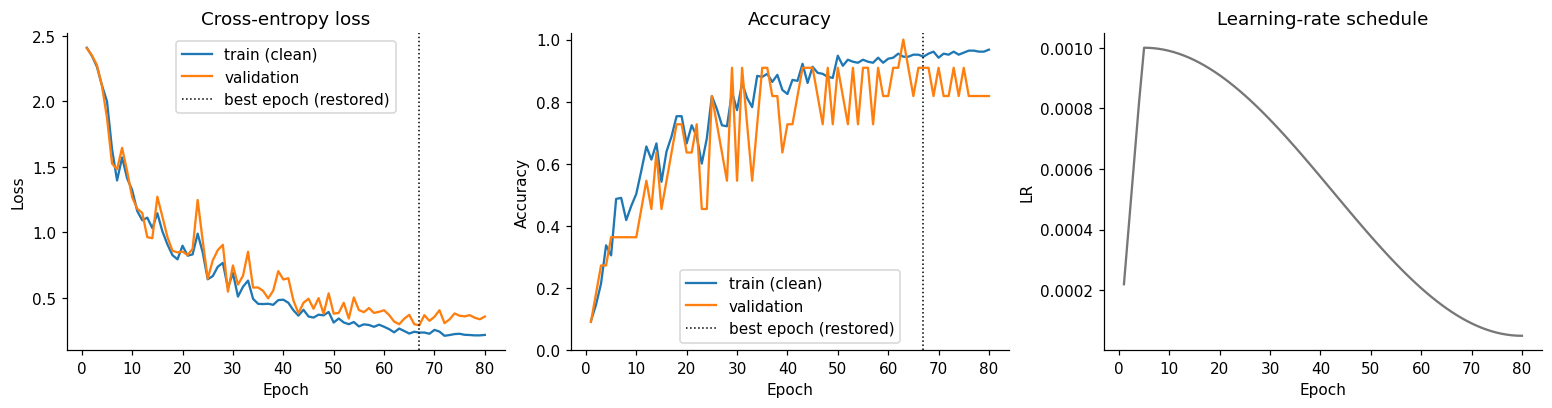

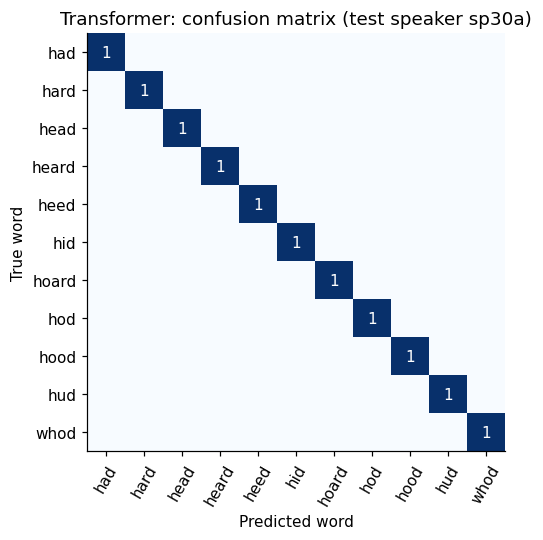

Failure cases (validation + test):
  [val] sp29a: true "heard" -> predicted "had" (confidence 0.44)
  [test] none


In [ ]:
TF_CFG = dict(d_model=64, n_heads=4, d_ff=128, n_layers=2, n_conv=2, dropout=0.1, pos='sinusoidal',
              attention_mode='learned')
TRAIN_CFG = dict(epochs=80, batch_size=32, lr=1e-3, weight_decay=1e-2, warmup_epochs=5, patience=25, spec_aug=True)


def build_transformer(seed=SEED, **overrides):
    """Seeded construction so that every run starts from reproducible initial weights."""
    torch.manual_seed(seed)
    return SpeechTransformer(N_FEATS, N_CLASSES, **{**TF_CFG, **overrides}).to(device=DEVICE, dtype=DTYPE)


print('Model config  :', TF_CFG)
print('Training config:', TRAIN_CFG, '| seed', SEED, '| device', DEVICE)
tf_model = build_transformer()
tf_hist = train_transformer(tf_model, tf_train, tf_val, seed=SEED, **TRAIN_CFG)
tf_val_res, tf_test_res = evaluate(tf_model, tf_val), evaluate(tf_model, tf_test)
print(f'\nParameters: {count_parameters(tf_model):,} | trained {tf_hist["epochs_run"]} epochs '
      f'(best epoch {tf_hist["best_epoch"] + 1}) in {tf_hist["train_time"]:.1f} s')
print(f'Validation accuracy: {tf_val_res["acc"]:.1%} ({int(round(tf_val_res["acc"] * len(tf_val)))}/{len(tf_val)})   '
      f'loss {tf_val_res["loss"]:.3f}')
print(f'TEST accuracy      : {tf_test_res["acc"]:.1%} ({int(round(tf_test_res["acc"] * len(tf_test)))}/{len(tf_test)})   '
      f'loss {tf_test_res["loss"]:.3f}')

# --- training curves ----------------------------------------------------------------------
ep = np.arange(1, len(tf_hist['val_loss']) + 1)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), layout='constrained')
axes[0].plot(ep, tf_hist['train_loss'], label='train (clean)'); axes[0].plot(ep, tf_hist['val_loss'], label='validation')
axes[0].set(title='Cross-entropy loss', xlabel='Epoch', ylabel='Loss')
axes[1].plot(ep, tf_hist['train_acc'], label='train (clean)'); axes[1].plot(ep, tf_hist['val_acc'], label='validation')
axes[1].set(title='Accuracy', xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1.02))
axes[2].plot(ep, tf_hist['lr'], color='#777'); axes[2].set(title='Learning-rate schedule', xlabel='Epoch', ylabel='LR')
for ax in axes[:2]:
    ax.axvline(tf_hist['best_epoch'] + 1, color='k', ls=':', lw=1, label='best epoch (restored)')
    ax.legend()
plt.show()


# --- confusion matrix + failure cases -------------------------------------------------------
def confusion_matrix(y_true, y_pred, n=N_CLASSES):
    cm = torch.zeros(n, n, dtype=torch.long)
    for t, p in zip(y_true.tolist(), y_pred.tolist()):
        cm[t, p] += 1
    return cm


def plot_confusion(cm, title, ax):
    im = ax.imshow(cm.numpy(), cmap='Blues')
    ax.set(title=title, xlabel='Predicted word', ylabel='True word', xticks=range(len(all_words)),
           yticks=range(len(all_words)), xticklabels=all_words, yticklabels=all_words)
    ax.tick_params(axis='x', rotation=60)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j] > 0:
                ax.text(j, i, int(cm[i, j]), ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    return im


fig, ax = plt.subplots(figsize=(5.4, 4.8), layout='constrained')
plot_confusion(confusion_matrix(tf_test.labels, tf_test_res['pred']), 'Transformer: confusion matrix (test speaker sp30a)', ax)
plt.show()

print('Failure cases (validation + test):')
for split, ds, res in [('val', tf_val, tf_val_res), ('test', tf_test, tf_test_res)]:
    probs = torch.softmax(res['logits'], dim=1)
    wrong = (res['pred'] != ds.labels).nonzero().flatten().tolist()
    for i in wrong:
        print(f'  [{split}] {records[ds.indices[i]]["speaker"]}: true "{all_words[ds.labels[i]]}" -> predicted '
              f'"{all_words[res["pred"][i]]}" (confidence {probs[i, res["pred"][i]]:.2f})')
    if not wrong:
        print(f'  [{split}] none')

**Qualitative analysis: what does the trained model attend to?** For three test words chosen to span the vowel space ("heed" front/close, "had" open, "whod" back/close) the figure shows (left) the log-mel spectrogram with the total attention each time position **receives** (column-mean of the attention matrix, i.e. how much the other tokens look at it), and (middle, right) the head-averaged attention matrices of layers 1 and 2. Row $i$ of a matrix says where token $i$ looks; a bright diagonal means "look at myself/neighbours", vertical stripes mean "everybody looks at the same frames".

A second figure splits layer 1 into its four heads for one word, to see whether heads specialise.

*How to read it for the report:* check (i) whether attention concentrates on the steady vowel segment rather than the silence at the edges, (ii) whether it is local (diagonal band) or global (stripes), (iii) whether heads differ, and (iv) whether layer 2 differs from layer 1. Describe what you actually see in your figures.

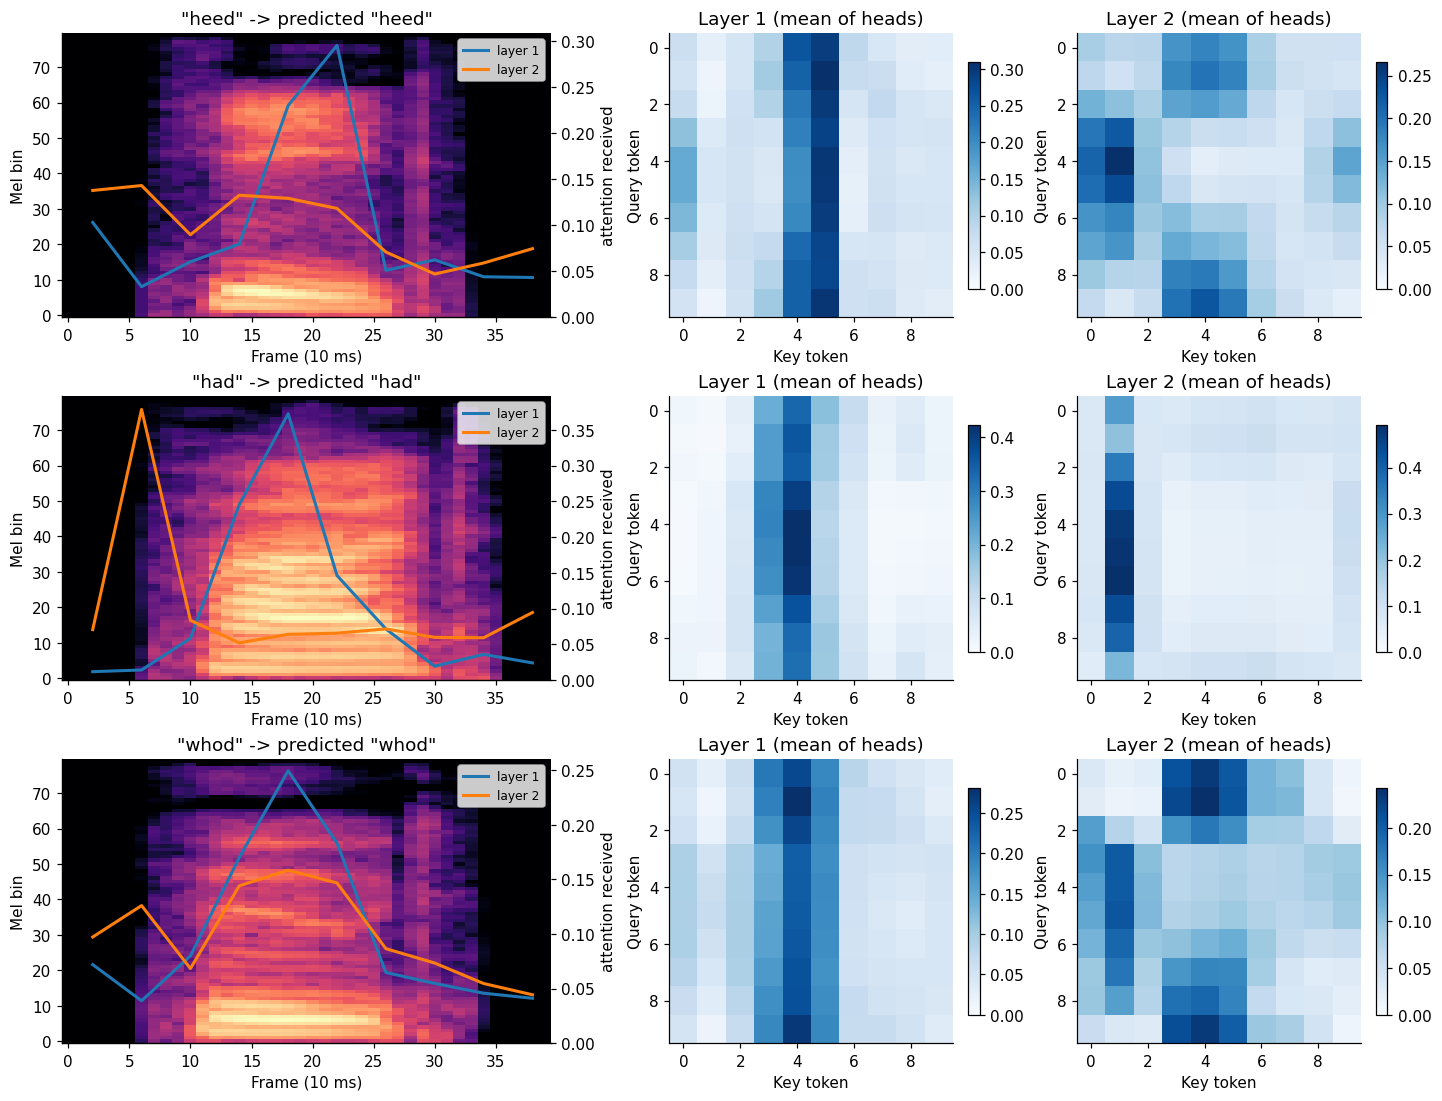

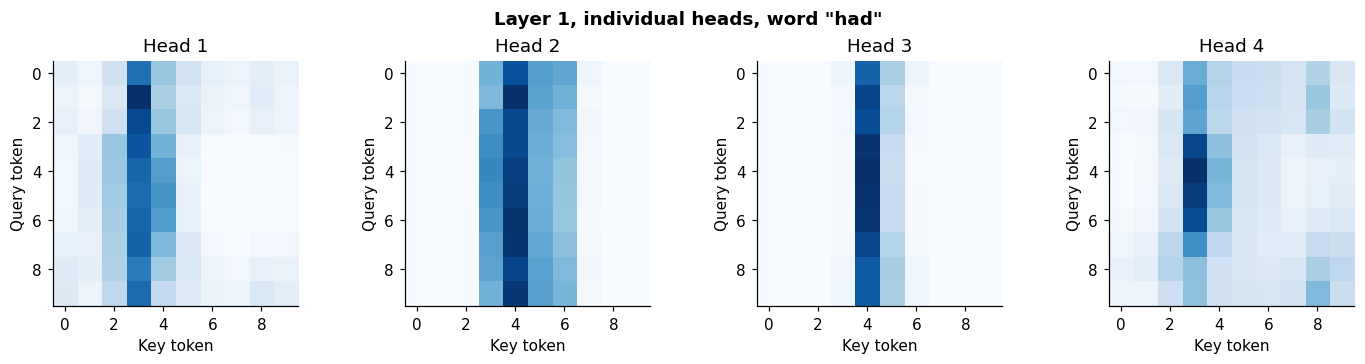

In [ ]:
@torch.no_grad()
def get_attention(model, ds, position):
    """Attention weights for ONE recording: list over layers of (H, T', T') tensors, plus real token count."""
    model.eval()
    x, L, y = ds.batch([position])
    logits, attn, mask = model(x, L, return_attn=True)
    t_out = int(mask.sum())
    return [a[0, :, :t_out, :t_out].cpu() for a in attn], logits[0].cpu()


def plot_attention(model, ds, words=('heed', 'had', 'whod')):
    n_conv = model.front.n_conv
    stride = 2 ** n_conv
    fig, axes = plt.subplots(len(words), 3, figsize=(13, 3.3 * len(words)), layout='constrained',
                             gridspec_kw={'width_ratios': [1.6, 1, 1]})
    for r, word in enumerate(words):
        pos = ds.labels.tolist().index(all_words.index(word))
        attn, logits = get_attention(model, ds, pos)
        raw = sequences[ds.indices[pos]]                                   # (T, 80) un-standardised log-mel
        T = raw.shape[0]
        ax = axes[r, 0]
        ax.imshow(raw.T.numpy(), origin='lower', aspect='auto', cmap='magma', vmin=-80, vmax=0)
        ax2 = ax.twinx()
        for li, a in enumerate(attn):
            received = a.mean(0).mean(0).numpy()                           # avg over heads, then over queries -> (T',)
            ax2.plot(np.arange(len(received)) * stride + stride / 2, received, lw=2, label=f'layer {li + 1}')
        ax2.set(ylim=(0, None), ylabel='attention received'); ax2.legend(loc='upper right', fontsize=8)
        pred = all_words[int(logits.argmax())]
        ax.set(title=f'"{word}" -> predicted "{pred}"', xlabel='Frame (10 ms)', ylabel='Mel bin')
        for li, a in enumerate(attn[:2]):
            im = axes[r, 1 + li].imshow(a.mean(0).numpy(), cmap='Blues', vmin=0)
            axes[r, 1 + li].set(title=f'Layer {li + 1} (mean of heads)', xlabel='Key token', ylabel='Query token')
            fig.colorbar(im, ax=axes[r, 1 + li], shrink=0.8)
    plt.show()


def plot_heads(model, ds, word='had', layer=0):
    pos = ds.labels.tolist().index(all_words.index(word))
    a = get_attention(model, ds, pos)[0][layer]                            # (H, T', T')
    fig, axes = plt.subplots(1, a.shape[0], figsize=(3.2 * a.shape[0], 3.2), layout='constrained')
    for h, ax in enumerate(np.atleast_1d(axes)):
        ax.imshow(a[h].numpy(), cmap='Blues', vmin=0)
        ax.set(title=f'Head {h + 1}', xlabel='Key token', ylabel='Query token')
    fig.suptitle(f'Layer {layer + 1}, individual heads, word "{word}"', fontweight='bold')
    plt.show()


plot_attention(tf_model, tf_test)
plot_heads(tf_model, tf_test, 'had', layer=0)

### 5.7 Comparison vs MLP (accuracy & parameter count)

To compare fairly with the MLP we need more than one 11-recording test set. Three complementary measurements are used:

1. **Five seeds** on the fixed split (train 28 speakers / validate `sp29a` / test `sp30a`): mean +/- std over random initialisations and augmentation draws.
2. **Speaker-independent 5-fold cross-validation** over the 29 development speakers (about 6 held-out speakers = about 64 recordings per fold, 319 predictions in total, no speaker ever in both train and held-out; each fold re-fits its own standardisation). `sp30a` is **not** touched. Folds use the same number of epochs as the main run (`CV_EPOCHS = 80`, no early stopping, because there is no validation speaker). Fewer epochs under-train the Transformer and would make the comparison unfair.
3. **Cost**: parameter count and training time.

**Runtime:** this cell trains about 35 small models (roughly 10-15 minutes on CPU).

The MLP baseline is the `SpeechFFN` architecture of 2.7 (80-64-32-11) on the time-averaged features, trained with Adam and early stopping for this comparison. If Part 3 produces a better-tuned MLP (dropout, SpecAugment, schedules), report that number in the final table too; the comparison code below only needs the new model swapped in.

| Model | Parameters | Train time (s) | Val acc (5 seeds) | Test acc (5 seeds) | Speaker-CV acc (5 folds) |
|---|---:|---:|---:|---:|---:|
| MLP 80-64-32-11 (pooled features) | 7,627 | 0.9 | 81.8% +/- 0.0% | 89.1% +/- 8.9% | 65.1% +/- 6.5% |
| Transformer (conv + 2 encoder layers) | 95,435 | 25.5 | 94.5% +/- 4.5% | 90.9% +/- 10.0% | 75.5% +/- 2.0% |

Pooled CV predictions: MLP 65.5% | Transformer 75.5%  (n = 319)
Per-fold CV accuracy  MLP        : [0.712 0.652 0.667 0.697 0.527]
Per-fold CV accuracy  Transformer: [0.727 0.788 0.758 0.758 0.745]
Per-seed test accuracy MLP / Transformer: [0.727 1.    0.909 0.909 0.909] / [1.    0.909 1.    0.909 0.727]


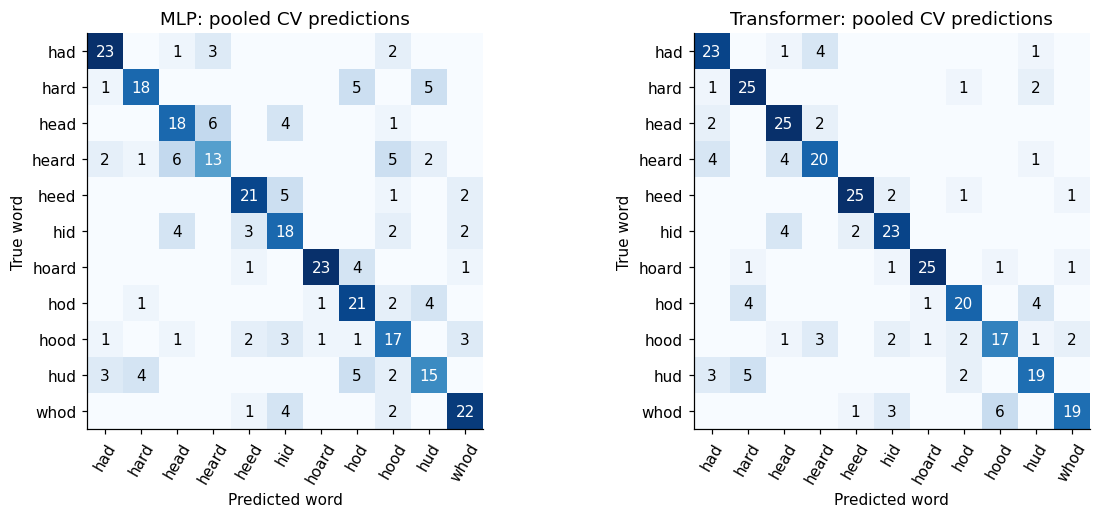

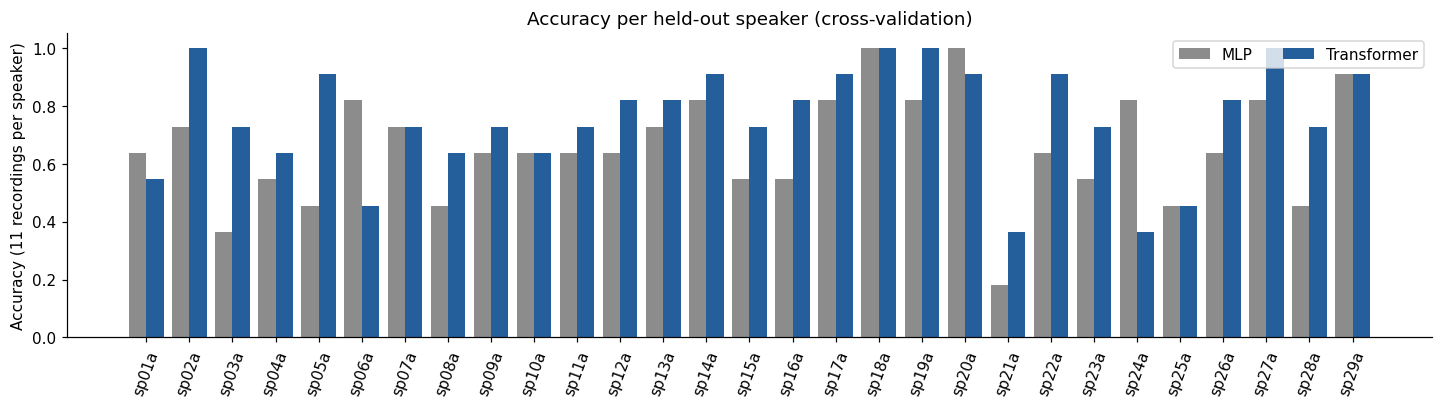

Hardest speakers for the Transformer: [('sp21a', 0.36), ('sp24a', 0.36), ('sp06a', 0.45), ('sp25a', 0.45)]
Speaker-to-speaker spread (std of per-speaker accuracy): MLP 0.19, Transformer 0.18


In [ ]:
SEEDS = [SEED + i for i in range(5)]
CV_FOLDS = 5
CV_EPOCHS = TRAIN_CFG['epochs']   # same epoch budget as the main run (40 epochs left the model under-trained: ~82% train acc)
CV_MLP_EPOCHS = 100


def train_mlp_baseline(X_tr, y_tr, X_va=None, y_va=None, seed=SEED, epochs=CV_MLP_EPOCHS, lr=1e-3, batch_size=32,
                       weight_decay=1e-4, patience=25):
    """Part 2's SpeechFFN (80-64-32-11) on pooled, standardised features. Adam + (optional) early stopping."""
    torch.manual_seed(seed)
    net = SpeechFFN().to(device=DEVICE, dtype=DTYPE)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    best, bad, t0 = {'loss': float('inf'), 'state': None}, 0, time.perf_counter()
    X_tr, y_tr = X_tr.to(DEVICE), y_tr.to(DEVICE)
    for epoch in range(epochs):
        net.train()
        perm = torch.randperm(len(X_tr))
        for i in range(0, len(X_tr), batch_size):
            idx = perm[i:i + batch_size]
            loss = F.cross_entropy(net(X_tr[idx]), y_tr[idx])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        if X_va is not None:
            net.eval()
            with torch.no_grad():
                vl = F.cross_entropy(net(X_va.to(DEVICE)), y_va.to(DEVICE)).item()
            if vl < best['loss'] - 1e-4:
                best, bad = {'loss': vl, 'state': copy.deepcopy(net.state_dict())}, 0
            else:
                bad += 1
                if bad >= patience:
                    break
    if best['state'] is not None:
        net.load_state_dict(best['state'])
    return net, time.perf_counter() - t0


@torch.no_grad()
def mlp_predict(net, X):
    net.eval()
    return net(X.to(DEVICE)).argmax(1).cpu()


# ---- (1) five seeds on the fixed split ---------------------------------------------------------
tf_runs, mlp_runs = [], []
for s in SEEDS:
    m = build_transformer(s)
    h = train_transformer(m, tf_train, tf_val, seed=s, verbose=False, **TRAIN_CFG)
    tf_runs.append((evaluate(m, tf_val)['acc'], evaluate(m, tf_test)['acc'], h['train_time'], count_parameters(m)))
    net, t = train_mlp_baseline(X_train, y_train, X_val, y_val, seed=s)
    mlp_runs.append(((mlp_predict(net, X_val) == y_val).float().mean().item(),
                     (mlp_predict(net, X_test) == y_test).float().mean().item(), t, count_parameters(net)))
tf_runs, mlp_runs = np.array(tf_runs), np.array(mlp_runs)


# ---- (2) speaker-independent cross-validation on the 29 development speakers --------------------
DEV_SPEAKERS = sorted(TRAIN_SPEAKERS | VAL_SPEAKERS)


def speaker_folds(k=CV_FOLDS, seed=SEED):
    order = np.random.default_rng(seed).permutation(DEV_SPEAKERS)
    for held in np.array_split(order, k):
        held = set(held.tolist())
        yield ([i for i, r in enumerate(records) if r['speaker'] in DEV_SPEAKERS and r['speaker'] not in held],
               [i for i, r in enumerate(records) if r['speaker'] in held])


def cv_transformer(k=CV_FOLDS, **overrides):
    """Returns (per-fold accuracy, true labels, predictions) pooled over the held-out folds."""
    accs, ys, ps = [], [], []
    for f, (tr, te) in enumerate(speaker_folds(k)):
        mean, std = fit_standardiser(tr)                                   # statistics from this fold's TRAIN speakers
        ds_tr, ds_te = SequenceDataset(tr, mean, std), SequenceDataset(te, mean, std)
        m = build_transformer(SEED + f, **overrides)
        train_transformer(m, ds_tr, None, seed=SEED + f, track_train=False, verbose=False, **{**TRAIN_CFG, 'epochs': CV_EPOCHS})
        r = evaluate(m, ds_te)
        accs.append(r['acc']); ys.append(ds_te.labels); ps.append(r['pred'])
    return np.array(accs), torch.cat(ys), torch.cat(ps)


def cv_mlp(k=CV_FOLDS):
    accs, ys, ps = [], [], []
    for f, (tr, te) in enumerate(speaker_folds(k)):
        mean = X_raw[tr].mean(0, keepdim=True)
        std = X_raw[tr].std(0, unbiased=False, keepdim=True).clamp_min(1e-5)
        net, _ = train_mlp_baseline((X_raw[tr] - mean) / std, y_all[tr], seed=SEED + f)
        pred = mlp_predict(net, (X_raw[te] - mean) / std)
        accs.append((pred == y_all[te]).float().mean().item()); ys.append(y_all[te]); ps.append(pred)
    return np.array(accs), torch.cat(ys), torch.cat(ps)


cv_tf_acc, cv_tf_y, cv_tf_p = cv_transformer()
cv_mlp_acc, cv_mlp_y, cv_mlp_p = cv_mlp()


# ---- results table -----------------------------------------------------------------------------
def pm(a):
    return f'{a.mean():.1%} +/- {a.std():.1%}'


rows = [('MLP 80-64-32-11 (pooled features)', mlp_runs, cv_mlp_acc), ('Transformer (conv + 2 encoder layers)', tf_runs, cv_tf_acc)]
table = ['| Model | Parameters | Train time (s) | Val acc (5 seeds) | Test acc (5 seeds) | Speaker-CV acc (5 folds) |',
         '|---|---:|---:|---:|---:|---:|']
for name, runs, cv in rows:
    table.append(f'| {name} | {int(runs[0, 3]):,} | {runs[:, 2].mean():.1f} | {pm(runs[:, 0])} | {pm(runs[:, 1])} | {pm(cv)} |')
display(Markdown('\n'.join(table)))
print(f'Pooled CV predictions: MLP {(cv_mlp_p == cv_mlp_y).float().mean():.1%} | '
      f'Transformer {(cv_tf_p == cv_tf_y).float().mean():.1%}  (n = {len(cv_tf_y)})')
print('Per-fold CV accuracy  MLP        :', np.round(cv_mlp_acc, 3))
print('Per-fold CV accuracy  Transformer:', np.round(cv_tf_acc, 3))
print('Per-seed test accuracy MLP / Transformer:', np.round(mlp_runs[:, 1], 3), '/', np.round(tf_runs[:, 1], 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')
plot_confusion(confusion_matrix(cv_mlp_y, cv_mlp_p), 'MLP: pooled CV predictions', axes[0])
plot_confusion(confusion_matrix(cv_tf_y, cv_tf_p), 'Transformer: pooled CV predictions', axes[1])
plt.show()

# ---- per-speaker accuracy (speaker variability is the main difficulty) -------------------------------
cv_speaker = np.array([records[i]['speaker'] for _, te in speaker_folds() for i in te])   # same order as the pooled predictions
spk_list = [str(s) for s in sorted(set(cv_speaker))]
spk_acc = {name: np.array([(p[cv_speaker == s] == y[cv_speaker == s]).float().mean().item() for s in spk_list])
           for name, (y, p) in {'MLP': (cv_mlp_y, cv_mlp_p), 'Transformer': (cv_tf_y, cv_tf_p)}.items()}
fig, ax = plt.subplots(figsize=(13, 3.6), layout='constrained')
xs = np.arange(len(spk_list))
ax.bar(xs - 0.2, spk_acc['MLP'], 0.4, label='MLP', color='#8c8c8c')
ax.bar(xs + 0.2, spk_acc['Transformer'], 0.4, label='Transformer', color='#245e9b')
ax.set(title='Accuracy per held-out speaker (cross-validation)', ylabel='Accuracy (11 recordings per speaker)',
       xticks=xs, xticklabels=spk_list, ylim=(0, 1.05))
ax.tick_params(axis='x', rotation=70); ax.legend(ncol=2)
plt.show()
hard = np.argsort(spk_acc['Transformer'])[:4]
print('Hardest speakers for the Transformer:', [(spk_list[i], round(float(spk_acc['Transformer'][i]), 2)) for i in hard])
print('Speaker-to-speaker spread (std of per-speaker accuracy): '
      f'MLP {spk_acc["MLP"].std():.2f}, Transformer {spk_acc["Transformer"].std():.2f}')

### 5.8 Analysis: does attention help? Effect of sequence length after subsampling

**Question 1: does attention help?** We isolate its contribution with an ablation, all measured with the same speaker-independent cross-validation as 5.7:

| Variant | What is removed |
|---|---|
| **A. No encoder** (`n_layers=0`) | Conv front-end + mean-pool + Linear only: no attention, no encoder FFN |
| **B. Uniform attention** (`attention_mode='uniform'`) | Full encoder (FFN, residuals, LayerNorm) but every token gets equal weight, so tokens are merely averaged and attention is **not content-dependent** |
| **C. Learned attention** (full model) | Nothing |

A $\to$ B shows the value of the extra non-linear layers; **B $\to$ C isolates what content-based attention itself adds.** Differences of one or two points are within fold-to-fold noise (see the std).

**Question 2: how does sequence length after subsampling affect computation?** For one layer with $T'$ tokens, width $d$ and FFN width $d_{ff}$ the multiply-accumulates (MACs) are

$$\underbrace{4T'd^2}_{Q,K,V,O\ \text{projections}}+\underbrace{2T'^2d}_{QK^\top\ \text{and}\ \text{weights}\cdot V}+\underbrace{2T'd\,d_{ff}}_{\text{FFN}} .$$

Projections and FFN grow **linearly** in $T'$; the attention score matrix grows **quadratically** (memory too: $H\times T'^2$ numbers per layer). Setting $2T'^2d=T'(4d^2+2d\,d_{ff})$ gives a crossover at $T^*=2d+d_{ff}$ tokens, above which the quadratic term dominates. Each stride-2 convolution halves $T'$ and so quarters the attention matrix. We vary `n_conv` in $\{0,1,2,3\}$ and record tokens, analytic MACs, measured inference time and cross-validated accuracy.

**Runtime:** this cell runs 5 more cross-validations (roughly 15-20 minutes on CPU).

| Variant | Parameters | Speaker-CV accuracy (mean +/- std over folds) | Pooled accuracy |
|---|---:|---:|---:|
| A. No encoder (conv + mean-pool) | 28,491 | 65.3% +/- 1.5% | 65.2% |
| B. Encoder, uniform attention | 95,435 | 70.5% +/- 2.0% | 70.5% |
| C. Encoder, learned attention (full) | 95,435 | 75.5% +/- 2.0% | 75.5% |

| n_conv | Tokens at T=55 | Attention matrix (entries/head) | MACs (x1e6) | Attention share | Inference (ms/recording) | Speaker-CV acc |
|---:|---:|---:|---:|---:|---:|---:|
| 0 | 55 | 3025 | 4.66 | 16.6% | 0.44 | 73.2% +/- 5.5% |
| 1 | 28 | 784 | 2.47 | 8.1% | 0.27 | 75.5% +/- 4.4% |
| 2 | 14 | 196 | 1.57 | 3.2% | 0.21 | 75.5% +/- 2.0% |
| 3 | 7 | 49 | 1.16 | 1.1% | 0.23 | 73.9% +/- 2.9% |

Quadratic attention cost overtakes the linear terms at about T* = 2d + d_ff = 256 tokens; a typical word has 55 tokens without subsampling and 14 with the default front-end.


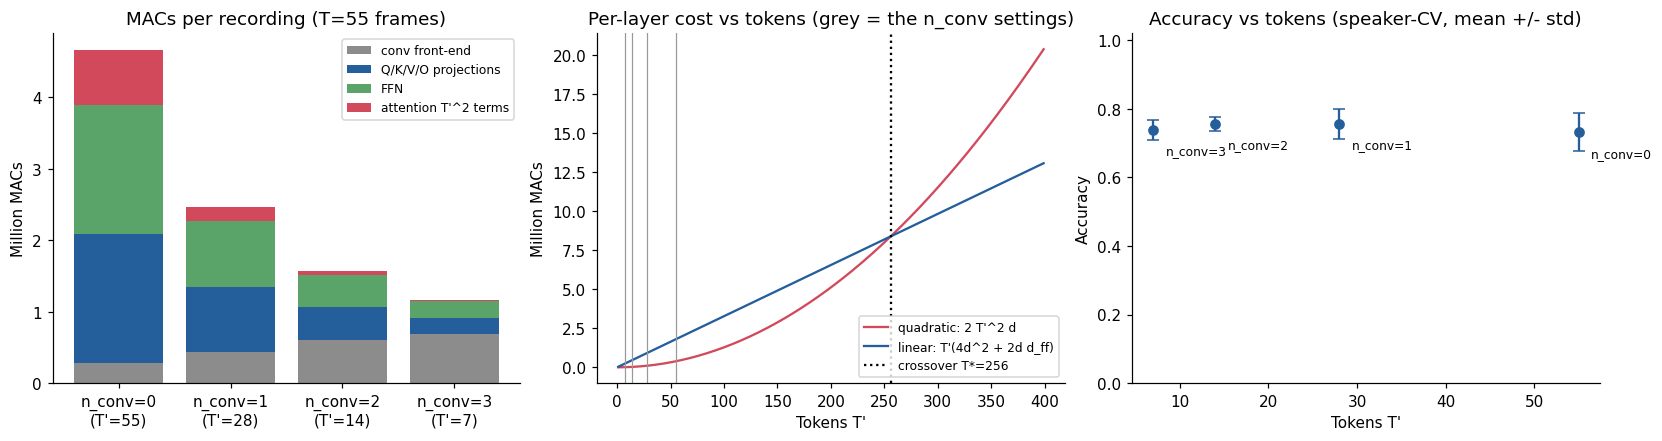

In [ ]:
# ---- Question 1: ablation (variant C reuses the full-model CV from 5.7) ----------------------------------
ablation = {'A. No encoder (conv + mean-pool)': cv_transformer(n_layers=0),
            'B. Encoder, uniform attention': cv_transformer(attention_mode='uniform'),
            'C. Encoder, learned attention (full)': (cv_tf_acc, cv_tf_y, cv_tf_p)}
rows = ['| Variant | Parameters | Speaker-CV accuracy (mean +/- std over folds) | Pooled accuracy |', '|---|---:|---:|---:|']
for name, (acc, y_true, y_pred) in ablation.items():
    cfg = {'A': dict(n_layers=0), 'B': dict(attention_mode='uniform'), 'C': {}}[name[0]]
    rows.append(f'| {name} | {count_parameters(build_transformer(**cfg)):,} | {pm(acc)} | {(y_pred == y_true).float().mean():.1%} |')
display(Markdown('\n'.join(rows)))

# ---- Question 2: sequence length vs compute ---------------------------------------------------------------
T_MED = int(tf_train.lengths.median())                                     # typical recording length in frames


def estimate_macs(T_in, n_conv, d=64, d_ff=128, n_layers=2, n_mels=80, k=3):
    """Analytic multiply-accumulates for ONE recording of T_in frames (see formula above)."""
    T, front, c_in = T_in, 0, n_mels
    if n_conv == 0:
        front = T * n_mels * d
    for _ in range(n_conv):
        T = (T - 1) // 2 + 1
        front += T * c_in * d * k
        c_in = d
    return {'tokens': T, 'front': front, 'proj': n_layers * 4 * T * d * d, 'attn': n_layers * 2 * T * T * d,
            'ffn': n_layers * 2 * T * d * d_ff}


@torch.no_grad()
def time_inference(model, ds, repeats=30, n=64):
    """Mean forward time per recording in ms for a batch of n recordings (after a warm-up pass)."""
    model.eval()
    x, L, _ = ds.batch(list(range(min(n, len(ds)))))
    for _ in range(3):
        model(x, L)
    t0 = time.perf_counter()
    for _ in range(repeats):
        model(x, L)
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - t0) / repeats / x.shape[0]


seq_rows, seq_results = ['| n_conv | Tokens at T=%d | Attention matrix (entries/head) | MACs (x1e6) | Attention share | Inference (ms/recording) | Speaker-CV acc |' % T_MED,
                         '|---:|---:|---:|---:|---:|---:|---:|'], {}
for n_conv in (0, 1, 2, 3):
    macs = estimate_macs(T_MED, n_conv, TF_CFG['d_model'], TF_CFG['d_ff'], TF_CFG['n_layers'], N_FEATS)
    total = macs['front'] + macs['proj'] + macs['attn'] + macs['ffn']
    acc = ablation['C. Encoder, learned attention (full)'][0] if n_conv == TF_CFG['n_conv'] else cv_transformer(n_conv=n_conv)[0]
    ms = time_inference(build_transformer(n_conv=n_conv), tf_val if len(tf_val) >= 8 else tf_train)
    seq_results[n_conv] = dict(macs=macs, total=total, acc=acc, ms=ms)
    seq_rows.append(f'| {n_conv} | {macs["tokens"]} | {macs["tokens"] ** 2} | {total / 1e6:.2f} | {macs["attn"] / total:.1%} | '
                    f'{ms:.2f} | {pm(acc)} |')
display(Markdown('\n'.join(seq_rows)))
T_star = 2 * TF_CFG['d_model'] + TF_CFG['d_ff']
print(f'Quadratic attention cost overtakes the linear terms at about T* = 2d + d_ff = {T_star} tokens; '
      f'a typical word has {estimate_macs(T_MED, 0)["tokens"]} tokens without subsampling and {estimate_macs(T_MED, 2)["tokens"]} with the default front-end.')

# ---- figure -----------------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), layout='constrained')
labels = [f'n_conv={n}\n(T\'={seq_results[n]["macs"]["tokens"]})' for n in seq_results]
bottom = np.zeros(4)
for key, colour, name in [('front', '#8c8c8c', 'conv front-end'), ('proj', '#245e9b', 'Q/K/V/O projections'),
                          ('ffn', '#5aa469', 'FFN'), ('attn', '#d1495b', 'attention T\'^2 terms')]:
    vals = np.array([seq_results[n]['macs'][key] for n in seq_results]) / 1e6
    axes[0].bar(labels, vals, bottom=bottom, color=colour, label=name)
    bottom += vals
axes[0].set(title=f'MACs per recording (T={T_MED} frames)', ylabel='Million MACs'); axes[0].legend(fontsize=8)
Ts = np.arange(1, 400)
d_m, dff_m = TF_CFG['d_model'], TF_CFG['d_ff']
axes[1].plot(Ts, 2 * Ts ** 2 * d_m / 1e6, color='#d1495b', label="quadratic: 2 T'^2 d")
axes[1].plot(Ts, Ts * (4 * d_m ** 2 + 2 * d_m * dff_m) / 1e6, color='#245e9b', label="linear: T'(4d^2 + 2d d_ff)")
axes[1].axvline(T_star, color='k', ls=':', label=f"crossover T*={T_star}")
for n in seq_results:
    axes[1].axvline(seq_results[n]['macs']['tokens'], color='#999', lw=0.8)
axes[1].set(title='Per-layer cost vs tokens (grey = the n_conv settings)', xlabel="Tokens T'", ylabel='Million MACs')
axes[1].legend(fontsize=8)
for n in seq_results:
    a = seq_results[n]['acc']
    axes[2].errorbar(seq_results[n]['macs']['tokens'], a.mean(), yerr=a.std(), fmt='o', capsize=4, color='#245e9b')
    axes[2].annotate(f'n_conv={n}', (seq_results[n]['macs']['tokens'], a.mean()), textcoords='offset points', xytext=(8, -16), fontsize=8)
axes[2].set(title='Accuracy vs tokens (speaker-CV, mean +/- std)', xlabel="Tokens T'", ylabel='Accuracy', ylim=(0, 1.02))
plt.show()

**Interpretation of the results (Balaji).** Numbers come from the tables above; "cross-validation" means speaker-independent 5-fold CV over the 29 development speakers (319 held-out recordings), and the 5.7 and 5.8 tables use the same folds.

* *Single split vs cross-validation.* On the fixed split the main run scores 90.9% (10/11) on the validation speaker and 100% (11/11) on the test speaker. With 11 recordings per set one word is 9.1 points, and over five seeds the Transformer's test accuracy ranges from 72.7% to 100% (std 10.0%), so these numbers cannot separate the models (MLP test accuracy 89.1% +/- 8.9%). Cross-validation is the reliable measure, and it gives lower absolute accuracy: MLP 65.1% +/- 6.5%, Transformer 75.5% +/- 2.0%.
* *Transformer vs MLP.* The Transformer is better in all five folds (for example 74.5% vs 52.7% in the last fold), by about 10 points on average, and it is far more consistent across folds (std 2.0% vs 6.5%). The cost is 12.5x more parameters (95,435 vs 7,627) and about 28x longer training (25.5 s vs 0.9 s on this CPU). The MLP baseline here is untuned; if Part 3's regularised MLP is better, the gap may narrow.
* *Does attention help?* In the ablation, the encoder without any attention-like mixing (A, conv front-end + mean-pool) reaches 65.3% +/- 1.5%, about the same as the MLP. Adding the encoder with uniform attention (B) gives 70.5% +/- 2.0%, and learned content-based attention (C) gives 75.5% +/- 2.0%. So about half of the gain over A comes from the extra encoder layers (residual connections, FFN, LayerNorm acting on the subsampled sequence) and about half from content-dependent attention. Each step is about 5 points, roughly 2.5 fold standard deviations, which is consistent evidence but not proof given only five folds. In the attention maps (5.6), layer 1 sends most attention to the few tokens covering the steady vowel segment (vertical stripes in the matrices, the same for every query token), which is where the vowel identity is carried; layer 2 is less uniform and for "had" concentrates on an early token.
* *Sequence length.* From `n_conv=0` to `3` the number of tokens falls from 55 to 7, the attention matrix from 3,025 to 49 entries per head, and the analytic cost from 4.66 to 1.16 million MACs, while the attention share of the cost falls from 16.6% to 1.1%. Cross-validated accuracy is 73.2%, 75.5%, 75.5% and 73.9% (stds 2.0-5.5%), so the differences are within noise: the default two stride-2 convolutions cut the cost by 66% compared with no subsampling at no measurable accuracy loss and with the lowest fold-to-fold std. Measured inference time per recording drops from 0.44 ms to 0.21 ms and then flattens (0.23 ms at `n_conv=3`), because for such a small model fixed overheads dominate. The quadratic attention term is small here because the crossover $T^*=2d+d_{ff}=256$ tokens is far above 55, so subsampling mainly saves the linear projection and FFN work.
* *Failure cases and speakers.* Errors concentrate on acoustically neighbouring vowels: had / head / heard (up to 4 confusions in each direction), who'd mistaken for hood (6 times), and hod / hud / hard (3-5 each). On the fixed split the one validation error was "heard" predicted as "had" with a confidence of only 0.44. Per-speaker accuracy ranges from 100% (for example sp02a, sp18a, sp19a, sp27a) down to 36% (sp21a, sp24a) with a similar spread for both models (std 0.18-0.19), so speaker variability, not the model class, is the main source of error.
* *Limitations.* Only 29 speakers, five folds and one training run per fold; differences of about 3 points or less should not be interpreted. Hyper-parameters were fixed in advance (not tuned on the held-out folds).

## Final Evaluation on Test Data

## Discussion Questions

### Why is the data-driven approach particularly powerful for speech?

### How does the √d_k scaling prevent vanishing gradients in the softmax?

### FFN on pooled features vs Transformer on full sequence: trade-offs

**Answer (Balaji): FFN on pooled features vs Transformer on the full sequence.**

*Pooling* reduces each recording to one 80-dimensional average spectrum. The FFN on that vector is tiny (7,627 parameters), trains in under a second, needs no padding, masking or positional information, and is easy to debug. But averaging over time discards the order and dynamics of the signal (formant transitions, duration, onset and offset), so words that differ mainly in their temporal pattern look similar.

The *Transformer* keeps the whole sequence, so attention can weight the informative frames, such as the steady vowel centre, and the model can use temporal structure. In our experiments this gave about 10 points higher speaker-independent accuracy (75.5% vs 65.1%) and much more stable results across folds. The price is 12.5x more parameters, about 28x longer training, more engineering (padding masks, positional encodings, warm-up schedule, augmentation) and more sensitivity to over-fitting when only 308 training recordings are available.

*Computation* grows linearly with length for the projections and FFN and quadratically for attention; with 14 tokens the attention term is only about 3% of the cost (it overtakes the linear terms at about 256 tokens), and stride-2 convolutions cut the cost by about 66% without hurting accuracy. For short isolated words a pooled MLP is a strong, cheap baseline; the Transformer is worth its cost when temporal structure matters, and its quadratic cost and data appetite become the main concern for long utterances.

## Stretch Objectives (optional)

## References & Third-Party Code Attribution

**Part 5 references (Balaji)**

* Vaswani, A. et al. (2017). *Attention Is All You Need.* NeurIPS. (Encoder architecture, scaled dot-product and multi-head attention, sinusoidal positional encoding, post-LN layout.)
* Park, D. S. et al. (2019). *SpecAugment: A Simple Data Augmentation Method for Automatic Speech Recognition.* Interspeech. (Frequency/time masking in `spec_augment`.)
* Loshchilov, I. and Hutter, F. (2019). *Decoupled Weight Decay Regularization.* ICLR. (`torch.optim.AdamW`.)
* Ba, J. L., Kiros, J. R. and Hinton, G. E. (2016). *Layer Normalization.* arXiv:1607.06450. (`nn.LayerNorm`.)
* Part 4.1 (`scaled_dot_product_attention`, adapted from Tutorial_3_Attention_Mechanisms.ipynb): used only as a cross-check in 5.3; the Part 5 attention is an independent implementation with padding mask. `nn.MultiheadAttention` is used **only as a test reference** in 5.3, never inside the model.
* Libraries: PyTorch `nn.Linear`, `nn.Conv1d`, `nn.LayerNorm`, `nn.Dropout`, `torch.optim.AdamW`, `LambdaLR`. No third-party model code was copied.